# Exploratory Data Analysis (EDA): Tyre Degradation and Telemetry Behavior

This notebook performs an exploratory analysis to understand how telemetry variables relate to tyre degradation.
The goal is to:
- Visually validate the `Combined_Degradation` label
- Identify trends and anomalies over laps or time
- Explore correlations between driver behavior and degradation


## Load Data and add features

In [1]:
import pandas as pd
import numpy as np
from assign_turns_to_df import assign_turns_to_dataframe
from degradation_components_full import (
    compute_friction_penalty,
    compute_thermal_aging_penalty,
    compute_asymmetric_penalty,
    compute_transient_penalty,
    compute_corner_g_loss_by_turn,
    compute_combined_degradation,
    estimate_per_tire_fx,
    estimate_slip_power
)
import matplotlib.pyplot as plt
import seaborn as sns

# Load your stint data
df1 = pd.read_csv("parquet_files\\master_12hz_1stint.csv")

laps_to_plot = np.arange(1,16)

df1 = df1[(df1["Lap"].isin(laps_to_plot))]

df1 = assign_turns_to_dataframe(df1, "turn_ranges_laguna_seca.csv")
df1["corner_g_loss"] = compute_corner_g_loss_by_turn(df1)
df1["LatG"] = df1["LatAccel"].abs()
df1["LongG"] = df1["LongAccel"].abs()
df1 = estimate_per_tire_fx(df1)
df1["slip_power"] = estimate_slip_power(df1)
df1["friction_penalty"] = compute_friction_penalty(df1)
df1["vulcan_penalty"] = compute_thermal_aging_penalty(df1)
df1["asym_penalty"] = compute_asymmetric_penalty(df1)
df1["transient_penalty"] = compute_transient_penalty(df1)
df1 = compute_combined_degradation(df1)
#df1 = df1.dropna(subset=["combined_degradation"]).reset_index(drop=True) # drop NaN scores - should be at beginning and end
df1.head(n=40)

,AirDensity,AirPressure,AirTemp,Alt,Brake,BrakeABSactive,BrakeABScutPct,BrakeRaw,CFSRrideHeight,Clutch,...,RFFx,LRFx,RRFx,slip_power,friction_penalty,vulcan_penalty,asym_penalty,transient_penalty,combined_degradation,deg_delta_3s
0,1.16734,98741.0,19.8105,228.135,0.0,0,100.0,0.0,0.057095,100.0,...,NaN,NaN,NaN,NaN,NaN,0.0,0.049171,NaN,NaN,NaN
1,1.16734,98741.0,19.8105,228.235,0.0,0,100.0,0.0,0.068157,100.0,...,NaN,NaN,NaN,NaN,NaN,0.0,0.046643,NaN,NaN,NaN
2,1.16734,98741.0,19.8105,228.435,0.0,0,100.0,0.0,0.056496,100.0,...,NaN,NaN,NaN,NaN,NaN,0.0,0.077836,NaN,NaN,NaN
3,1.16734,98741.0,19.8105,228.635,0.0,0,100.0,0.0,0.056252,100.0,...,NaN,NaN,NaN,NaN,NaN,0.0,0.076212,NaN,NaN,NaN
4,1.16734,98741.0,19.8105,228.835,0.0,0,100.0,0.0,0.062708,100.0,...,69.419857,99.559744,107.831531,0.194928,0.022238,0.0,0.083229,NaN,NaN,NaN
5,1.16734,98741.0,19.8105,228.935,0.0,0,100.0,0.0,0.064552,100.0,...,69.733119,101.205984,108.296461,0.214583,0.024480,0.0,0.044650,NaN,NaN,NaN
6,1.16734,98741.0,19.8105,229.135,0.0,0,100.0,0.0,0.061417,100.0,...,68.193670,95.372723,105.987408,0.203118,0.023172,0.0,0.074297,NaN,NaN,NaN
7,1.16734,98741.0,19.8105,229.335,0.0,0,100.0,0.0,0.053342,100.0,...,66.199805,90.199924,102.968369,0.191048,0.021796,0.0,0.119076,NaN,NaN,NaN
8,1.16734,98741.0,19.8105,229.535,0.0,0,100.0,0.0,0.050296,100.0,...,60.950690,84.261098,94.929304,0.128546,0.014665,0.0,0.088727,NaN,NaN,NaN
9,1.16734,98741.0,19.8105,229.735,0.0,0,100.0,0.0,0.053253,100.0,...,62.276235,84.848006,96.969703,0.140177,0.015992,0.0,0.119330,NaN,NaN,NaN


## EDA of Basic Inputs

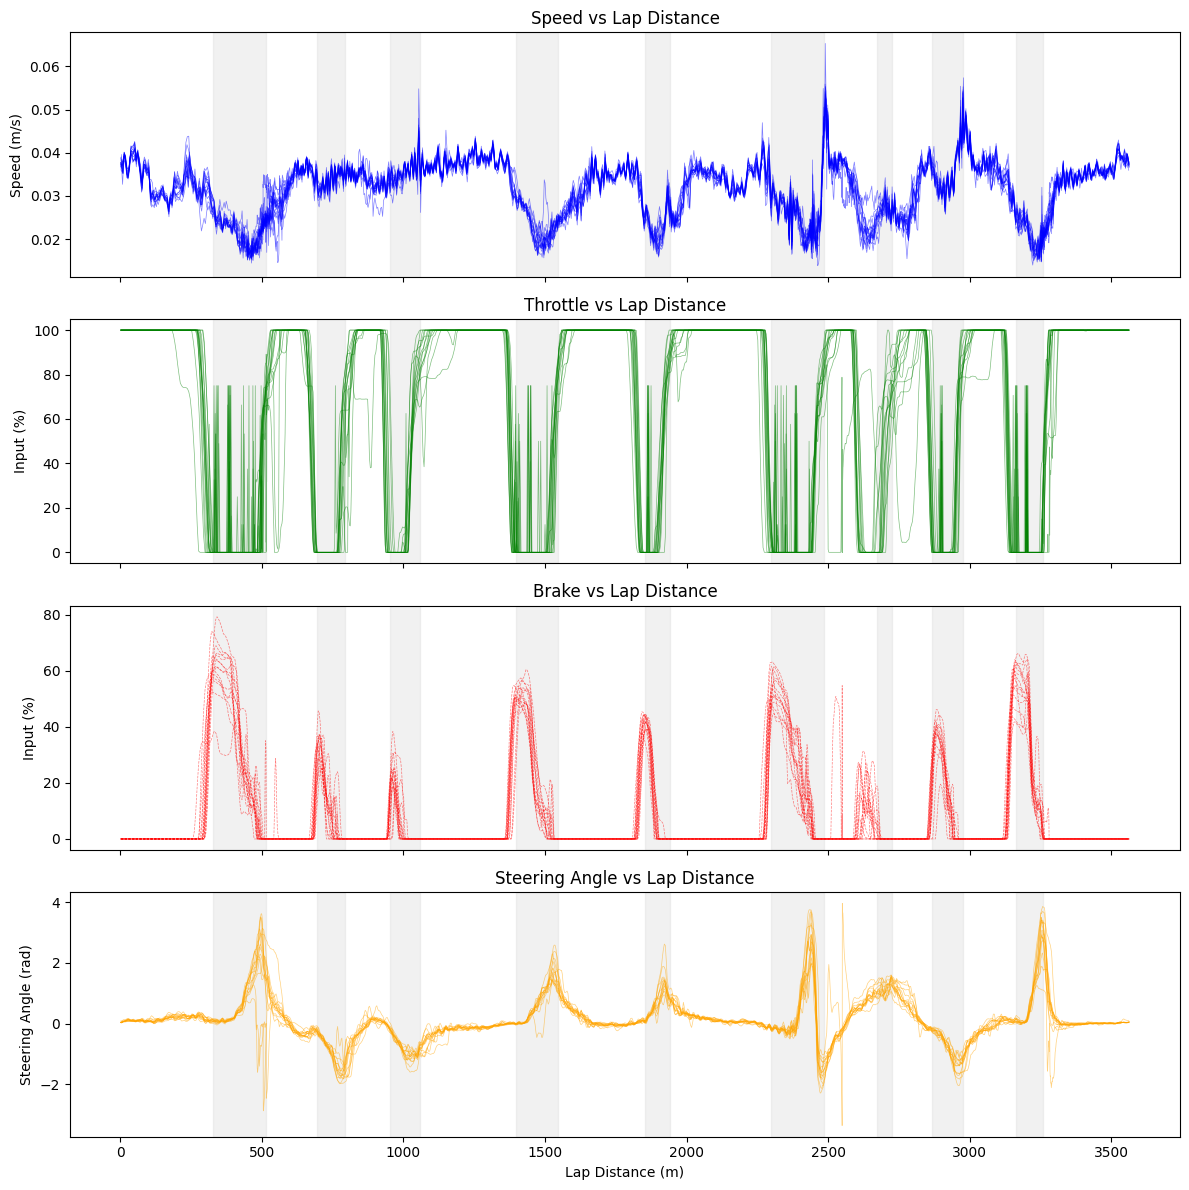

In [ ]:
# PLOTS OF THROTTLE, BRAKE, SPEED AND STEERING ANGLE

# Create overlay plots
fig, axs = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

for stint_num, stint_df1 in df1.groupby("source_file"):
    for lap_num, lap_df1 in stint_df1.groupby("Lap"):
        #axs[0].plot(lap_df1["LapDist"], lap_df1["Speed"], color="blue", alpha=0.5, linewidth=0.5)
        axs[0].plot(lap_df1["LapDist"], lap_df1["LRshockDefl"], color="blue", alpha=0.5, linewidth=0.5)
        axs[1].plot(lap_df1["LapDist"], lap_df1["Throttle"], label="Throttle (%)", color="green", alpha=0.5, linewidth=0.5)
        #axs[1].plot(lap_df1["LapDist"], lap_df1["LFshockDefl"], label="Throttle (%)", color="blue", alpha=0.5, linewidth=0.5)
        
        axs[2].plot(lap_df1["LapDist"], lap_df1["Brake"], color="red", alpha=0.5, linewidth=0.5, label="Brake (%)", linestyle="--")
        axs[3].plot(lap_df1["LapDist"], lap_df1["SteeringWheelAngle"], color="orange", alpha=0.5, linewidth=0.5)


# Speed
axs[0].set_ylabel("Speed (m/s)")
axs[0].set_title("Speed vs Lap Distance")

# Throttle
axs[1].set_ylabel("Input (%)")
axs[1].set_title("Throttle vs Lap Distance")

# Brake
#axs[1].plot(df1_p["LapDist (m)"], df1_p["Brake (%)"], label="Brake (%)", linestyle="--")
axs[2].set_ylabel("Input (%)")
axs[2].set_title("Brake vs Lap Distance")
#axs[1].legend()

# Steering
axs[3].set_ylabel("Steering Angle (rad)")
axs[3].set_xlabel("Lap Distance (m)")
axs[3].set_title("Steering Angle vs Lap Distance")


# Assume you're plotting only one lap (e.g., lap 9)
lap = 1
lap_df = df1[df1['Lap'] == lap].copy()
lap_df["in_turn"] = lap_df["Turn"].notna()

# Use LapDistance instead of SessionTime
in_turn_mask = lap_df["in_turn"].astype(int).diff().fillna(0)

for idx in lap_df.index:
    if in_turn_mask.loc[idx] == 1:  # start of turn
        start_dist = lap_df.at[idx, "LapDist"]
    elif in_turn_mask.loc[idx] == -1:  # end of turn
        end_dist = lap_df.at[idx, "LapDist"]
        axs[0].axvspan(start_dist, end_dist, color="lightgray", alpha=0.3)
        axs[1].axvspan(start_dist, end_dist, color="lightgray", alpha=0.3)
        axs[2].axvspan(start_dist, end_dist, color="lightgray", alpha=0.3)
        axs[3].axvspan(start_dist, end_dist, color="lightgray", alpha=0.3)

# Handle case where final row is still in a turn
if lap_df["in_turn"].iloc[-1] and in_turn_mask.iloc[-1] == 0:
    axs[0].axvspan(start_dist, lap_df["LapDist"].iloc[-1], color="lightgray", alpha=0.3)
    axs[1].axvspan(start_dist, lap_df["LapDist"].iloc[-1], color="lightgray", alpha=0.3)
    axs[1].axvspan(start_dist, lap_df["LapDist"].iloc[-1], color="lightgray", alpha=0.3)
    axs[1].axvspan(start_dist, lap_df["LapDist"].iloc[-1], color="lightgray", alpha=0.3)



plt.tight_layout()
plt.show()

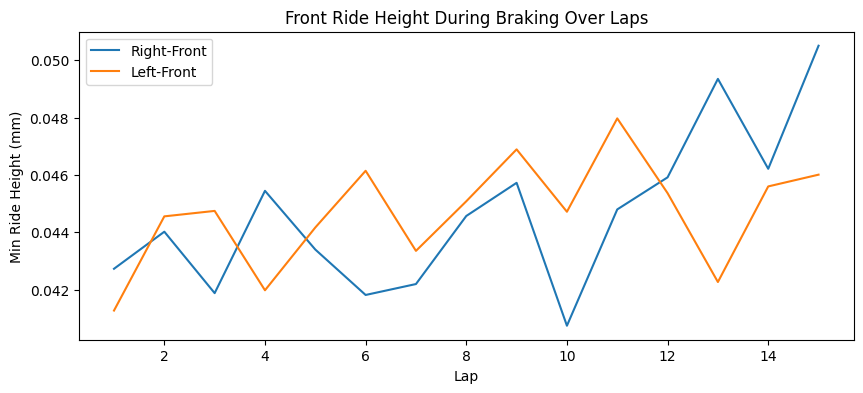

In [3]:
brake_threshold = 0.2
speed_threshold = 33  # km/h or adjust as needed

braking_df = df1[(df1["Brake"] > brake_threshold) & (df1["Speed"] > speed_threshold)]

# For each lap, get min ride height during braking
ride_summary = braking_df.groupby("Lap").agg({
    "RFrideHeight": "min",
    "LFrideHeight": "min",
    "LRrideHeight": "min",
    "RRrideHeight": "min",
    "Speed": "mean"
}).reset_index()

# Plot
plt.figure(figsize=(10, 4))
plt.plot(ride_summary["Lap"], ride_summary["RFrideHeight"], label="Right-Front")
plt.plot(ride_summary["Lap"], ride_summary["LFrideHeight"], label="Left-Front")
#plt.plot(ride_summary["Lap"], ride_summary["LRrideHeight"], label="LR")
#plt.plot(ride_summary["Lap"], ride_summary["RRrideHeight"], label="RR")
plt.xlabel("Lap")
plt.ylabel("Min Ride Height (mm)")
plt.title("Front Ride Height During Braking Over Laps")
plt.grid(False)
plt.legend()
plt.show()


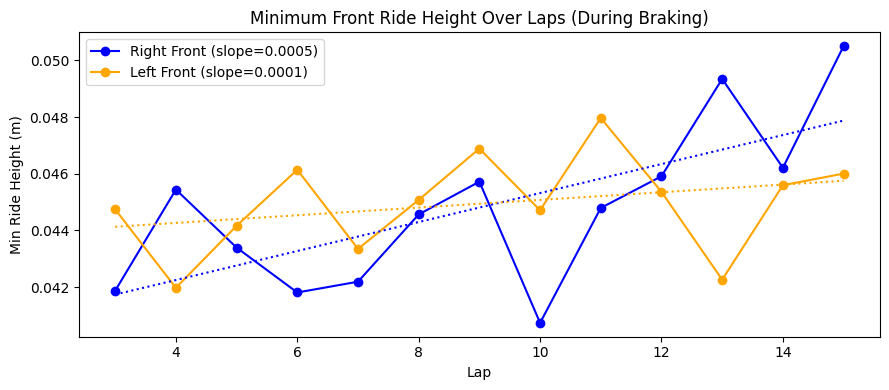

   RF_slope  LF_slope  RF_start_height  RF_end_height  LF_start_height  \
0  0.000512  0.000135         0.041876       0.050503         0.044743   

   LF_end_height  RF_delta_height  LF_delta_height  Total_Laps  
0       0.046007         0.008628         0.001264          13  


In [91]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Filter for high-speed braking events
brake_threshold = 0.2
speed_threshold = 33  # meters per second (~119 km/h)
braking_df1 = df1[(df1["Brake"] > brake_threshold) & (df1["Speed"] > speed_threshold)]

# Group by lap and calculate minimum front ride height
ride_summary = braking_df1.groupby("Lap").agg({
    "RFrideHeight": "min",
    "LFrideHeight": "min",
    "Speed": "mean"
}).reset_index()

# Linear regression on ride height vs lap
X = ride_summary["Lap"].values.reshape(-1, 1)
y_rf = ride_summary["RFrideHeight"].values
y_lf = ride_summary["LFrideHeight"].values

lr_rf = LinearRegression().fit(X, y_rf)
lr_lf = LinearRegression().fit(X, y_lf)

# Predict trendlines
y_rf_pred = lr_rf.predict(X)
y_lf_pred = lr_lf.predict(X)

# Plot ride height trend
plt.figure(figsize=(9, 4))
plt.plot(ride_summary["Lap"], y_rf, label=f"Right Front (slope={lr_rf.coef_[0]:.4f})", marker='o', color="Blue")
plt.plot(ride_summary["Lap"], y_lf, label=f"Left Front (slope={lr_lf.coef_[0]:.4f})", marker='o', color="Orange")
#plt.plot(ride_summary["Lap"], y_rf_pred, '--', label=f"RF Trent (slope={lr_rf.coef_[0]:.4f})")
plt.plot(ride_summary["Lap"], y_rf_pred, ':', color="Blue")
#plt.plot(ride_summary["Lap"], y_lf_pred, '--', label=f"LF Trend (slope={lr_lf.coef_[0]:.4f})")
plt.plot(ride_summary["Lap"], y_lf_pred, ':', color = "Orange")
plt.xlabel("Lap")
plt.ylabel("Min Ride Height (m)")
plt.title("Minimum Front Ride Height Over Laps (During Braking)")
plt.grid(False)
plt.legend()
plt.tight_layout()
plt.show()

# Summary metrics
metrics = {
    "RF_slope": lr_rf.coef_[0],
    "LF_slope": lr_lf.coef_[0],
    "RF_start_height": y_rf[0],
    "RF_end_height": y_rf[-1],
    "LF_start_height": y_lf[0],
    "LF_end_height": y_lf[-1],
    "RF_delta_height": y_rf[-1] - y_rf[0],
    "LF_delta_height": y_lf[-1] - y_lf[0],
    "Total_Laps": ride_summary["Lap"].max() - ride_summary["Lap"].min() + 1
}

ride_trend_metrics = pd.DataFrame([metrics])
print(ride_trend_metrics)


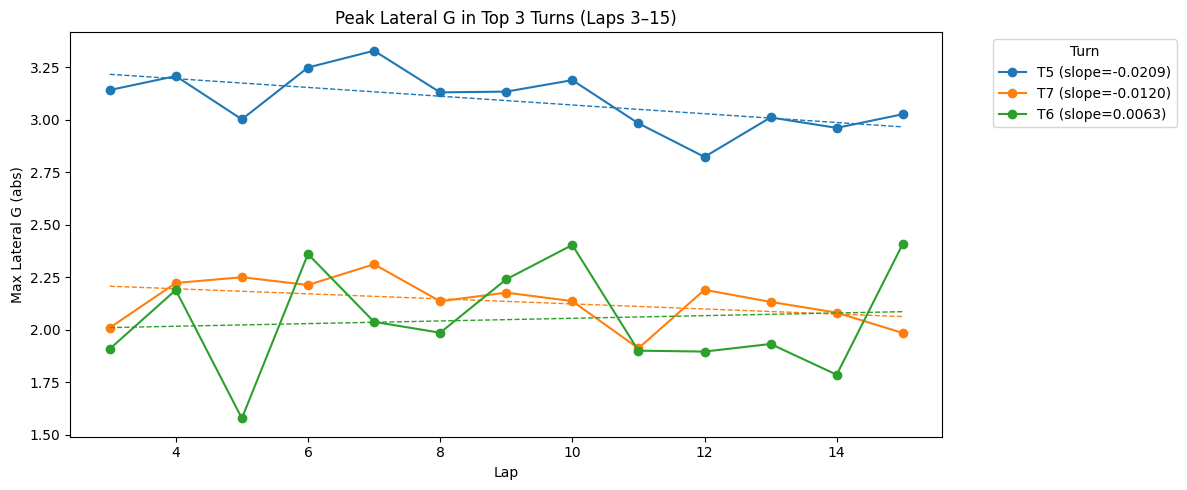

In [81]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# --- CONFIGURATION ---
min_lap = 3
max_lap = 15
exclude_turn = "T8"  # Set to None to keep all turns

# --- Load data ---
#df1 = pd.read_csv("master_12hz_1stint.csv")


# --- Assign Turns ---
turn_df1 = pd.read_csv("turn_ranges_laguna_seca.csv")
df1["LapDistPct"] = pd.to_numeric(df1["LapDistPct"], errors="coerce")
df1["Turn"] = None
for _, row in turn_df1.iterrows():
    mask = (df1["LapDistPct"] >= row["start_pct"]) & (df1["LapDistPct"] < row["end_pct"])
    df1.loc[mask, "Turn"] = row["Turn"]

# --- Filter to laps and turns ---
df1 = df1[(df1["Lap"] >= min_lap) & (df1["Lap"] <= max_lap)]
cornering_df1 = df1[df1["LatG"] > 0.5]
if exclude_turn:
    cornering_df1 = cornering_df1[cornering_df1["Turn"] != exclude_turn]

# --- Max LatG per Turn per Lap ---
latg_by_turn_lap = cornering_df1.groupby(["Lap", "Turn"])["LatG"].max().reset_index()

# --- Get Top 3 Turns by Avg G ---
top_turns = (
    latg_by_turn_lap.groupby("Turn")["LatG"]
    .mean()
    .sort_values(ascending=False)
    .head(3)
    .index
)

filtered = latg_by_turn_lap[latg_by_turn_lap["Turn"].isin(top_turns)]

# --- Pivot for plotting ---
latg_pivot = filtered.pivot(index="Lap", columns="Turn", values="LatG")

# --- Plot with matching-color regression lines ---
plt.figure(figsize=(12, 5))

for turn in top_turns:
    data = latg_pivot[turn].dropna()
    X = data.index.values.reshape(-1, 1)
    y = data.values

    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    # Plot actual points and get the color
    line, = plt.plot(data.index, y, marker='o', label=f"{turn} (slope={model.coef_[0]:.4f})")
    plt.plot(data.index, y_pred, linestyle='--', linewidth=1, color=line.get_color())

plt.title(f"Peak Lateral G in Top 3 Turns (Laps {min_lap}–{max_lap})")
plt.ylabel("Max Lateral G (abs)")
plt.xlabel("Lap")
plt.grid(False)
plt.legend(title="Turn", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


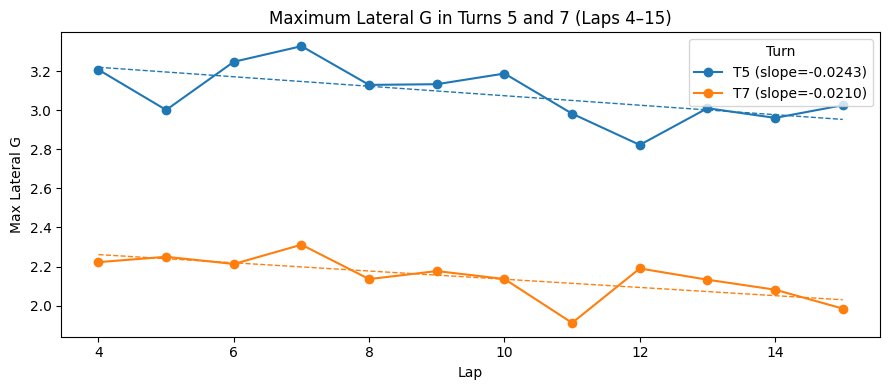

In [88]:
# --- Filter to just T5 and T7, between laps 3–15 ---
selected_turns = ["T5", "T7"]

filtered = latg_by_turn_lap[
    (latg_by_turn_lap["Turn"].isin(selected_turns)) &
    (latg_by_turn_lap["Lap"].between(4, 15))
]

# --- Pivot for plotting ---
latg_pivot = filtered.pivot(index="Lap", columns="Turn", values="LatG")

# --- Plot with matching-color regression lines ---
plt.figure(figsize=(9, 4))

for turn in selected_turns:
    data = latg_pivot[turn].dropna()
    X = data.index.values.reshape(-1, 1)
    y = data.values

    model = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    line, = plt.plot(data.index, y, marker='o', label=f"{turn} (slope={model.coef_[0]:.4f})")
    plt.plot(data.index, y_pred, linestyle='--', linewidth=1, color=line.get_color())

plt.title("Maximum Lateral G in Turns 5 and 7 (Laps 4–15)")
plt.ylabel("Max Lateral G")
plt.xlabel("Lap")
plt.grid(False)
#plt.legend(title="Turn", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.legend(title="Turn", loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


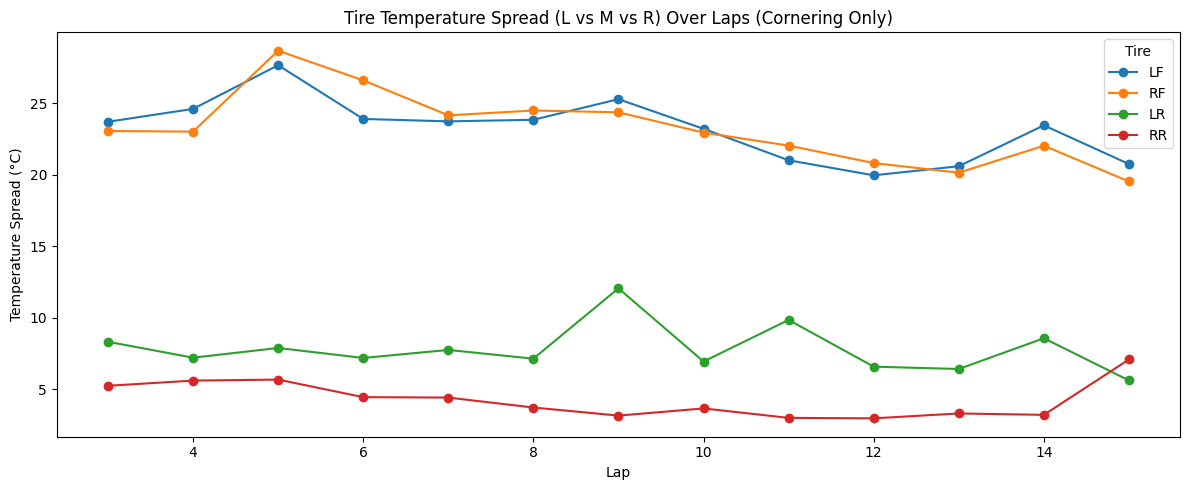

In [93]:
import pandas as pd
import matplotlib.pyplot as plt


# Compute absolute lateral G
#df["LatG"] = df["LatAccel"].abs()

# Filter to aggressive cornering only
cornering_df = df1[df1["LatG"] > 0.5].copy()

# Compute temperature spread (max - min of L/M/R) for each tire
for tire in ["LF", "RF", "LR", "RR"]:
    temp_cols = [f"{tire}tempL", f"{tire}tempM", f"{tire}tempR"]
    cornering_df[f"{tire}_temp_spread"] = (
        cornering_df[temp_cols].max(axis=1) - cornering_df[temp_cols].min(axis=1)
    )

# Group by lap and average the spread
spread_df = cornering_df.groupby("Lap")[
    ["LF_temp_spread", "RF_temp_spread", "LR_temp_spread", "RR_temp_spread"]
].mean().reset_index()

# Plot the spread per tire over laps
plt.figure(figsize=(12, 5))
for col in ["LF_temp_spread", "RF_temp_spread", "LR_temp_spread", "RR_temp_spread"]:
    plt.plot(spread_df["Lap"], spread_df[col], marker='o', label=col.split('_')[0])

plt.title("Tire Temperature Spread (L vs M vs R) Over Laps (Cornering Only)")
plt.xlabel("Lap")
plt.ylabel("Temperature Spread (°C)")
plt.grid(False)
plt.legend(title="Tire")
plt.tight_layout()
plt.show()


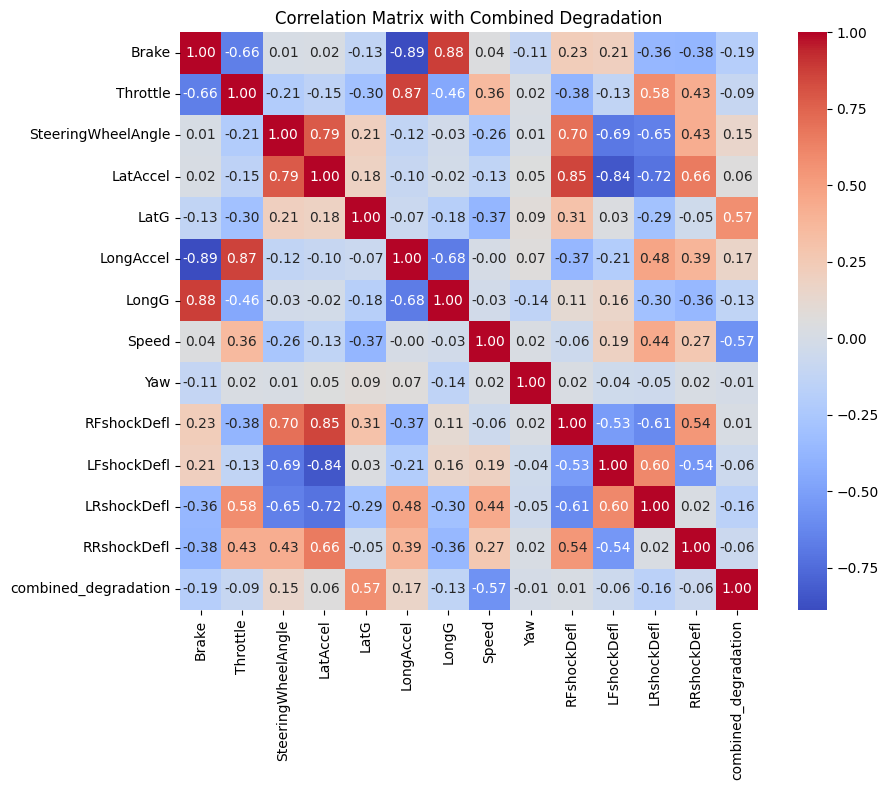

In [99]:
df1["LongG"] = df1["LongAccel"].abs()

telemetry_vars = ["Brake", "Throttle", "SteeringWheelAngle", "LatAccel", "LatG","LongAccel","LongG", "Speed", "Yaw", "RFshockDefl", "LFshockDefl", "LRshockDefl", "RRshockDefl"]

corr = df1[telemetry_vars + ["combined_degradation"]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix with Combined Degradation")
plt.tight_layout()
plt.show()

In [101]:
import pandas as pd

# Step 1: Load your dataset
#df = pd.read_csv("master_12hz_1stint.csv")

# Step 2: Import your degradation component functions
from degradation_components_full import (
    estimate_per_tire_fx,
    compute_combined_degradation
)

# Step 3: Compute degradation components
df1 = estimate_per_tire_fx(df1)
df1 = compute_combined_degradation(df1)

# Step 4: Select key features for the main report
main_features = [
    "Brake", "Throttle", "LatAccel", "LatG", "LongG", "LongAccel",
    "LFtempM", "combined_degradation"
]

main_stats = df1[main_features].describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]

# Step 5: Compute full stats for all numeric columns (for appendix)
full_stats = df1.describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]

# Step 6: Save outputs
#main_stats.to_excel("Main_Telemetry_Stats.xlsx")
#full_stats.to_excel("Appendix_B_Telemetry_Summary.xlsx")

# Optional: print the main stats to console
print("Main Stats for Report:")
print(main_stats)


Main Stats for Report:
                           mean        std           min        25%  \
Brake                  7.994421  15.796431 -1.862650e-07   0.000000   
Throttle              61.419512  43.880648 -1.862650e-07   0.000000   
LatAccel               0.177196   0.963316 -2.546660e+00  -0.494236   
LatG                   0.797043   0.569259  2.460520e-05   0.277198   
LongG                  0.448367   0.285432  7.027230e-05   0.279595   
LongAccel             -0.000675   0.531525 -1.618080e+00  -0.393500   
LFtempM               56.887001   8.641761  4.514310e+01  50.882475   
combined_degradation   0.109508   0.097016  2.276677e-04   0.036624   

                            50%         75%         max  
Brake                  0.000000    8.152625   74.089500  
Throttle              87.612000  100.000000  100.000000  
LatAccel               0.150514    1.007148    3.327820  
LatG                   0.738434    1.264985    3.327820  
LongG                  0.383401    0.526918    

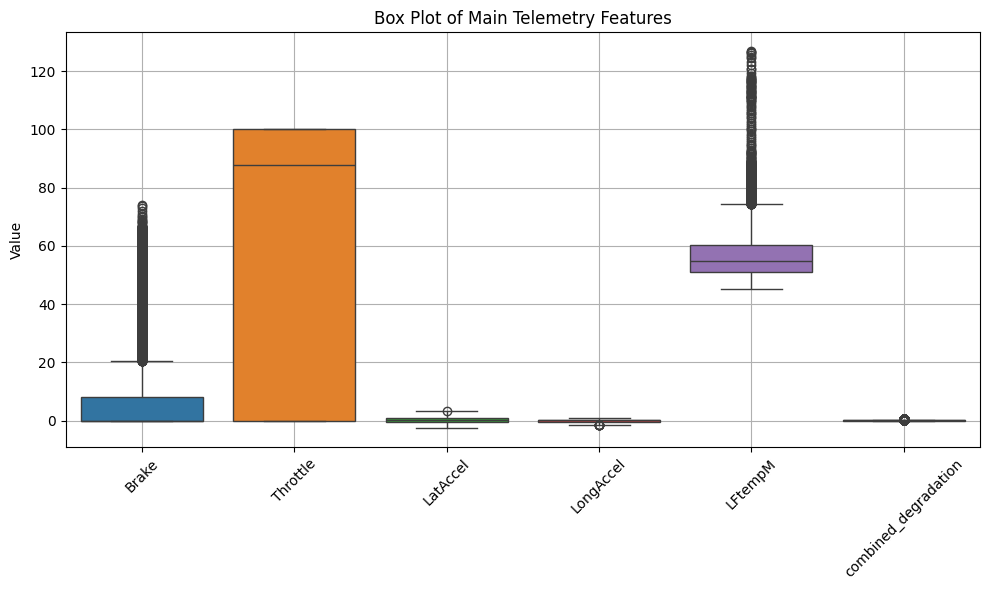

In [103]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load your data (adjust path as needed)
#df = pd.read_csv("master_12hz_1stint.csv")

# If needed, import and compute degradation label
from degradation_components_full import estimate_per_tire_fx, compute_combined_degradation
df1 = estimate_per_tire_fx(df1)
df1 = compute_combined_degradation(df1)

# Define the main telemetry features you want to visualize
main_features = [
    "Brake", "Throttle", "LatAccel", "LongAccel",
    "LFtempM", "combined_degradation"
]

# Plot the box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df1[main_features])
plt.title("Box Plot of Main Telemetry Features")
plt.ylabel("Value")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


## Step 2: Combined Degradation Distribution

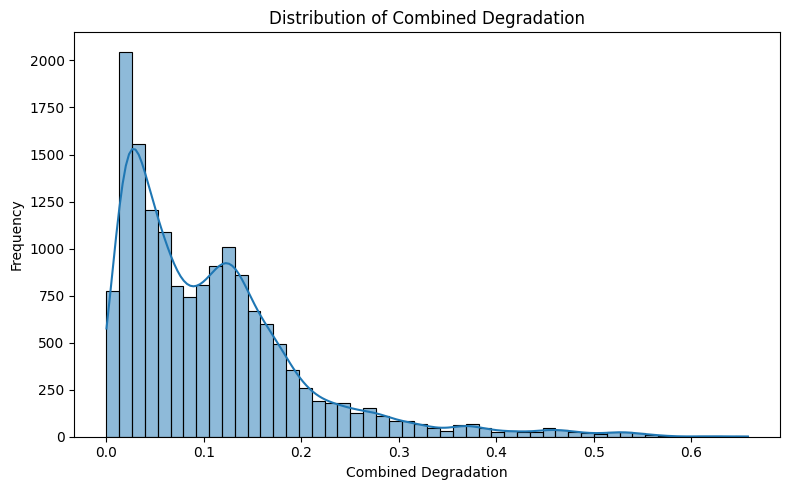

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df1["combined_degradation"], bins=50, kde=True)
plt.title("Distribution of Combined Degradation")
plt.xlabel("Combined Degradation")
plt.ylabel("Frequency")
plt.grid(False)
plt.tight_layout()
plt.show()

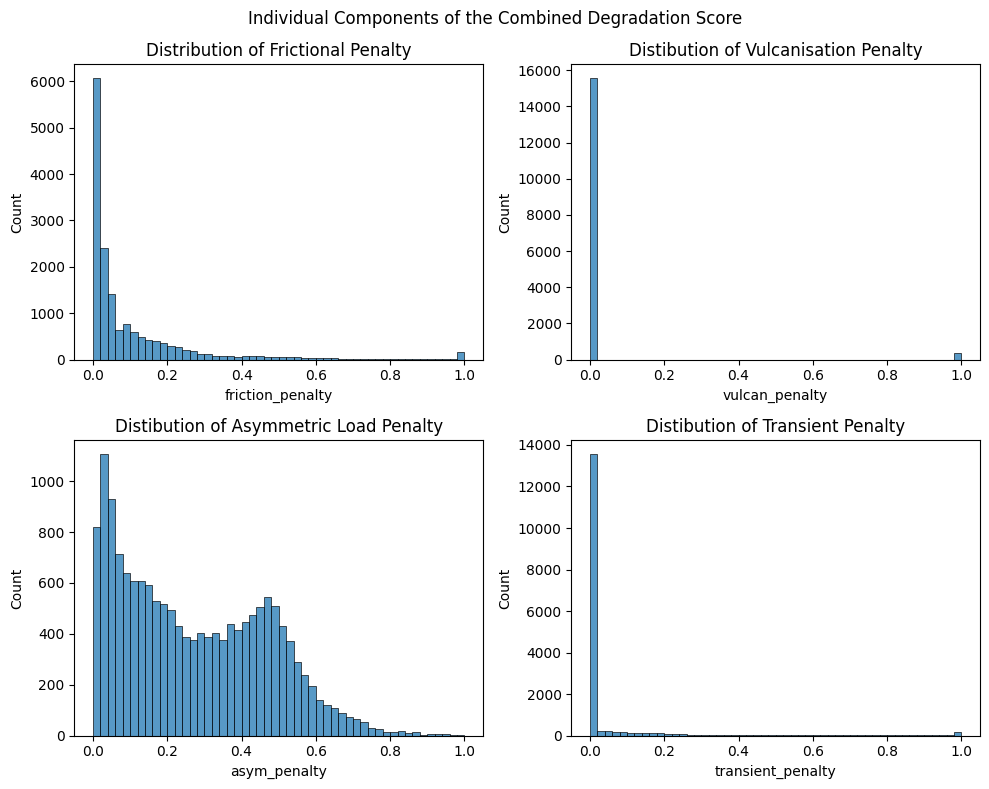

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

fig.suptitle('Individual Components of the Combined Degradation Score')

# Plot bar graphs in each subplot
#axes[0, 0].hist(df["frictional_penalty"], bins=50)
sns.histplot(ax=axes[0,0], data=df1["friction_penalty"], bins=50, kde=False)
axes[0, 0].set_title('Distribution of Frictional Penalty')


#axes[0, 1].hist(df["vulcanisation_penalty"], bins=50)
sns.histplot(ax=axes[0,1], data=df1["vulcan_penalty"], bins=50, kde=False)
axes[0, 1].set_title('Distibution of Vulcanisation Penalty')

# axes[1, 0].bar(x, y3)
sns.histplot(ax=axes[1,0], data=df1["asym_penalty"], bins=50, kde=False)
axes[1, 0].set_title('Distibution of Asymmetric Load Penalty')

# axes[1, 1].bar(x, y4)
sns.histplot(ax=axes[1,1], data=df1["transient_penalty"], bins=50, kde=False)
axes[1, 1].set_title('Distibution of Transient Penalty')
# axes[1, 1].set_title('Plot 4')

# Adjust layout
plt.tight_layout()
plt.show()

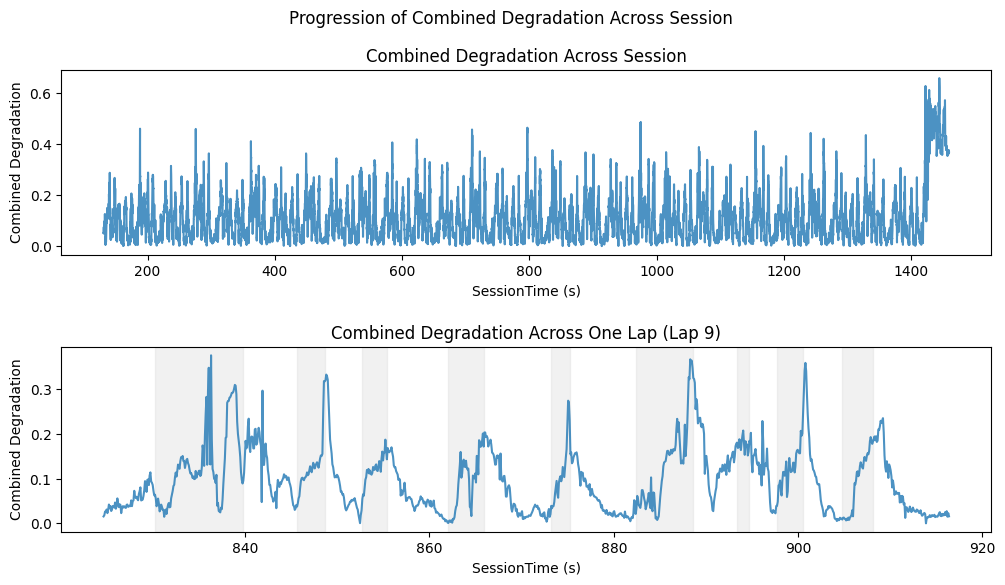

<Figure size 1200x300 with 0 Axes>

In [16]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

fig.suptitle('Progression of Combined Degradation Across Session')

plt.subplots_adjust(hspace=0.5)

plt.figure(figsize=(12, 3))

axs[0].plot(df1["SessionTime"], df1["combined_degradation"], label="Combined Degradation", alpha=0.8)
axs[0].set_ylabel("Combined Degradation")
axs[0].set_xlabel("SessionTime (s)")
axs[0].set_title("Combined Degradation Across Session")

lap= 9
axs[1].plot(df1[df1['Lap']==lap]["SessionTime"], df1[df1['Lap']==lap]["combined_degradation"], label="Combined Degradation", alpha=0.8)
axs[1].set_ylabel("Combined Degradation")
axs[1].set_xlabel("SessionTime (s)")
axs[1].set_title(f"Combined Degradation Across One Lap (Lap {lap})")


# Shade turn regions on the lap plot
lap_df = df1[df1['Lap'] == lap].copy()
lap_df["in_turn"] = lap_df["Turn"].notna()

# Find start/end boundaries of each turn region
in_turn_mask = lap_df["in_turn"].astype(int).diff().fillna(0)

for idx in lap_df.index:
    if in_turn_mask.loc[idx] == 1:  # start of turn
        start_time = lap_df.at[idx, "SessionTime"]
    elif in_turn_mask.loc[idx] == -1:  # end of turn
        end_time = lap_df.at[idx, "SessionTime"]
        axs[1].axvspan(start_time, end_time, color="lightgray", alpha=0.3)

# Handle case where final row is still in a turn
if lap_df["in_turn"].iloc[-1] and in_turn_mask.iloc[-1] == 0:
    axs[1].axvspan(start_time, lap_df["SessionTime"].iloc[-1], color="lightgray", alpha=0.3)
#plt.tight_layout()
plt.show()

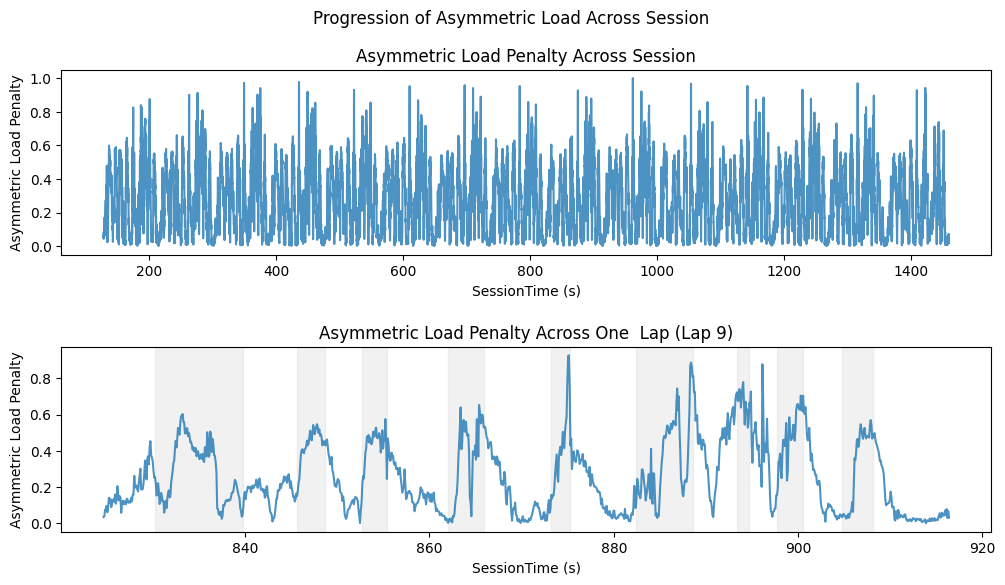

<Figure size 1200x300 with 0 Axes>

In [17]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

fig.suptitle('Progression of Asymmetric Load Across Session')

plt.subplots_adjust(hspace=0.5)

plt.figure(figsize=(12, 3))

axs[0].plot(df1["SessionTime"], df1["asym_penalty"], label="Asymmetric Load", alpha=0.8)
axs[0].set_ylabel("Asymmetric Load Penalty")
axs[0].set_xlabel("SessionTime (s)")
axs[0].set_title("Asymmetric Load Penalty Across Session")

lap= 9
axs[1].plot(df1[df1['Lap']==lap]["SessionTime"], df1[df1['Lap']==lap]["asym_penalty"], label="Asymmetric Load", alpha=0.8)
axs[1].set_ylabel("Asymmetric Load Penalty")
axs[1].set_xlabel("SessionTime (s)")
axs[1].set_title(f"Asymmetric Load Penalty Across One  Lap (Lap {lap})")

# Shade turn regions on the lap plot
lap_df = df1[df1['Lap'] == lap].copy()
lap_df["in_turn"] = lap_df["Turn"].notna()

# Find start/end boundaries of each turn region
in_turn_mask = lap_df["in_turn"].astype(int).diff().fillna(0)

for idx in lap_df.index:
    if in_turn_mask.loc[idx] == 1:  # start of turn
        start_time = lap_df.at[idx, "SessionTime"]
    elif in_turn_mask.loc[idx] == -1:  # end of turn
        end_time = lap_df.at[idx, "SessionTime"]
        axs[1].axvspan(start_time, end_time, color="lightgray", alpha=0.3)

# Handle case where final row is still in a turn
if lap_df["in_turn"].iloc[-1] and in_turn_mask.iloc[-1] == 0:
    axs[1].axvspan(start_time, lap_df["SessionTime"].iloc[-1], color="lightgray", alpha=0.3)

#plt.tight_layout()
plt.show()

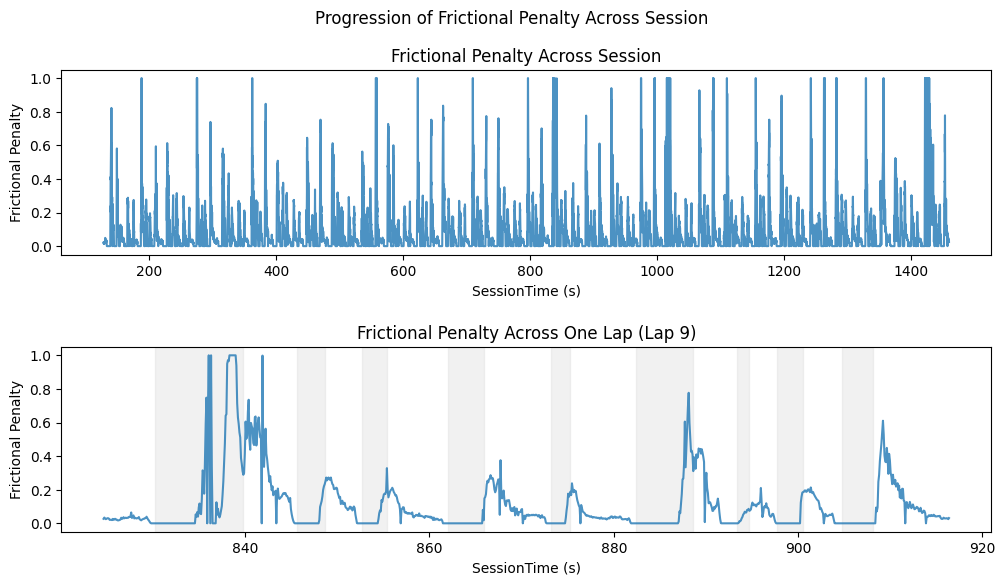

<Figure size 1200x300 with 0 Axes>

In [18]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

fig.suptitle('Progression of Frictional Penalty Across Session')

plt.subplots_adjust(hspace=0.5)

plt.figure(figsize=(12, 3))

axs[0].plot(df1["SessionTime"], df1["friction_penalty"], label="Frictional Penalty", alpha=0.8)
axs[0].set_ylabel("Frictional Penalty")
axs[0].set_xlabel("SessionTime (s)")
axs[0].set_title("Frictional Penalty Across Session")

lap= 9
axs[1].plot(df1[df1['Lap']==lap]["SessionTime"], df1[df1['Lap']==lap]["friction_penalty"], label="Frictional Penalty", alpha=0.8)
axs[1].set_ylabel("Frictional Penalty")
axs[1].set_xlabel("SessionTime (s)")
axs[1].set_title(f"Frictional Penalty Across One Lap (Lap {lap})")

# Shade turn regions on the lap plot
lap_df = df1[df1['Lap'] == lap].copy()
lap_df["in_turn"] = lap_df["Turn"].notna()

# Find start/end boundaries of each turn region
in_turn_mask = lap_df["in_turn"].astype(int).diff().fillna(0)

for idx in lap_df.index:
    if in_turn_mask.loc[idx] == 1:  # start of turn
        start_time = lap_df.at[idx, "SessionTime"]
    elif in_turn_mask.loc[idx] == -1:  # end of turn
        end_time = lap_df.at[idx, "SessionTime"]
        axs[1].axvspan(start_time, end_time, color="lightgray", alpha=0.3)

# Handle case where final row is still in a turn
if lap_df["in_turn"].iloc[-1] and in_turn_mask.iloc[-1] == 0:
    axs[1].axvspan(start_time, lap_df["SessionTime"].iloc[-1], color="lightgray", alpha=0.3)


#plt.tight_layout()
plt.show()

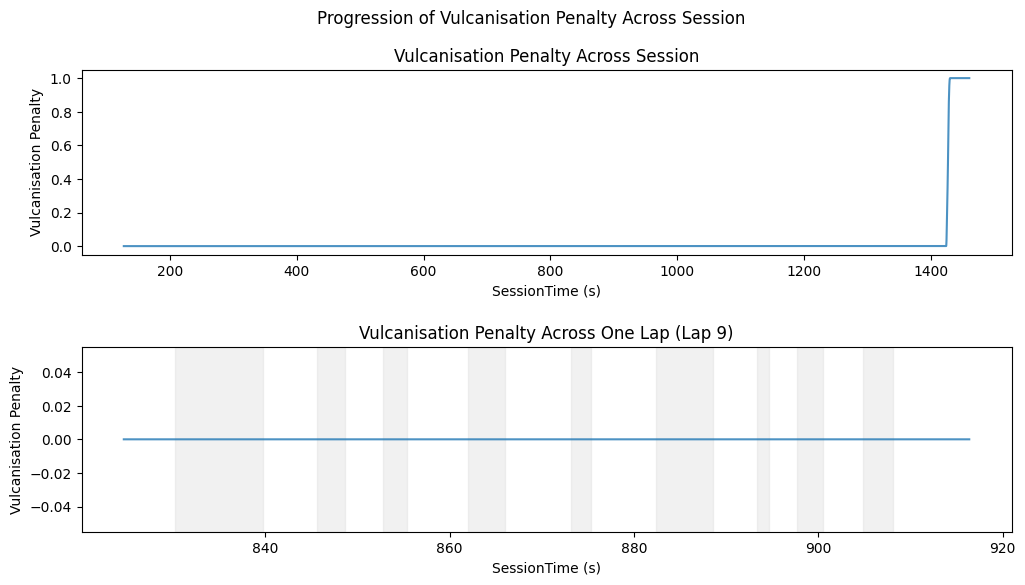

<Figure size 1200x300 with 0 Axes>

In [19]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

fig.suptitle('Progression of Vulcanisation Penalty Across Session')

plt.subplots_adjust(hspace=0.5)

plt.figure(figsize=(12, 3))

axs[0].plot(df1["SessionTime"], df1["vulcan_penalty"], label="Vulcanisation Penalty", alpha=0.8)
axs[0].set_ylabel("Vulcanisation Penalty")
axs[0].set_xlabel("SessionTime (s)")
axs[0].set_title("Vulcanisation Penalty Across Session")

lap= 9
axs[1].plot(df1[df1['Lap']==lap]["SessionTime"], df1[df1['Lap']==lap]["vulcan_penalty"], label="Vulcanisation Penalty", alpha=0.8)
axs[1].set_ylabel("Vulcanisation Penalty")
axs[1].set_xlabel("SessionTime (s)")
axs[1].set_title(f"Vulcanisation Penalty Across One Lap (Lap {lap})")

# Shade turn regions on the lap plot
lap_df = df1[df1['Lap'] == lap].copy()
lap_df["in_turn"] = lap_df["Turn"].notna()

# Find start/end boundaries of each turn region
in_turn_mask = lap_df["in_turn"].astype(int).diff().fillna(0)

for idx in lap_df.index:
    if in_turn_mask.loc[idx] == 1:  # start of turn
        start_time = lap_df.at[idx, "SessionTime"]
    elif in_turn_mask.loc[idx] == -1:  # end of turn
        end_time = lap_df.at[idx, "SessionTime"]
        axs[1].axvspan(start_time, end_time, color="lightgray", alpha=0.3)

# Handle case where final row is still in a turn
if lap_df["in_turn"].iloc[-1] and in_turn_mask.iloc[-1] == 0:
    axs[1].axvspan(start_time, lap_df["SessionTime"].iloc[-1], color="lightgray", alpha=0.3)

#plt.tight_layout()
plt.show()

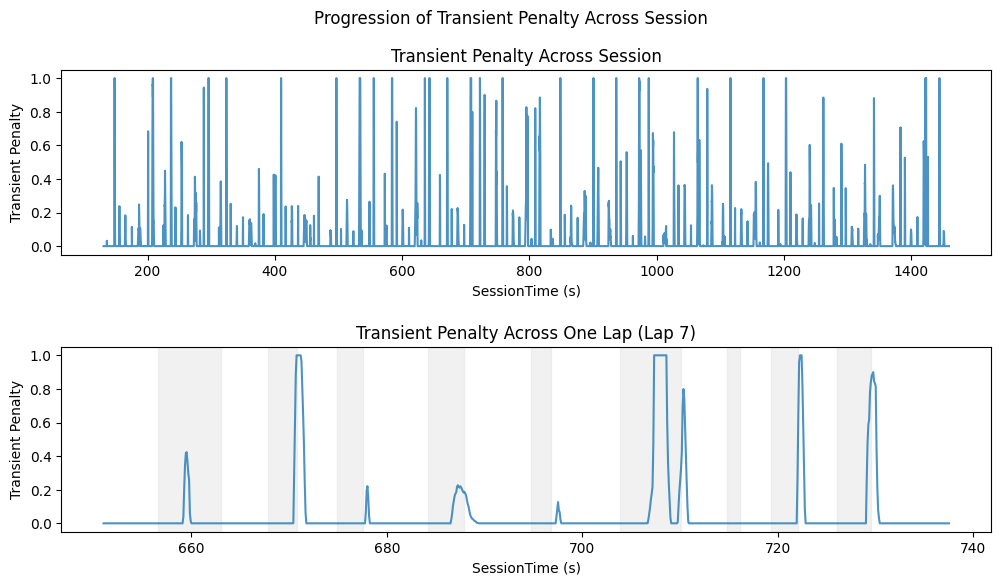

<Figure size 1200x300 with 0 Axes>

In [20]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

fig.suptitle('Progression of Transient Penalty Across Session')

plt.subplots_adjust(hspace=0.5)

plt.figure(figsize=(12, 3))

axs[0].plot(df1["SessionTime"], df1["transient_penalty"], label="Transient Penalty", alpha=0.8)
axs[0].set_ylabel("Transient Penalty")
axs[0].set_xlabel("SessionTime (s)")
axs[0].set_title("Transient Penalty Across Session")

lap= 7
axs[1].plot(df1[df1['Lap']==lap]["SessionTime"], df1[df1['Lap']==lap]["transient_penalty"], label="Transient Penalty", alpha=0.8)
axs[1].set_ylabel("Transient Penalty")
axs[1].set_xlabel("SessionTime (s)")
axs[1].set_title(f"Transient Penalty Across One Lap (Lap {lap})")

# Shade turn regions on the lap plot
lap_df = df1[df1['Lap'] == lap].copy()
lap_df["in_turn"] = lap_df["Turn"].notna()

# Find start/end boundaries of each turn region
in_turn_mask = lap_df["in_turn"].astype(int).diff().fillna(0)

for idx in lap_df.index:
    if in_turn_mask.loc[idx] == 1:  # start of turn
        start_time = lap_df.at[idx, "SessionTime"]
    elif in_turn_mask.loc[idx] == -1:  # end of turn
        end_time = lap_df.at[idx, "SessionTime"]
        axs[1].axvspan(start_time, end_time, color="lightgray", alpha=0.3)

# Handle case where final row is still in a turn
if lap_df["in_turn"].iloc[-1] and in_turn_mask.iloc[-1] == 0:
    axs[1].axvspan(start_time, lap_df["SessionTime"].iloc[-1], color="lightgray", alpha=0.3)
    
#plt.tight_layout()
plt.show()

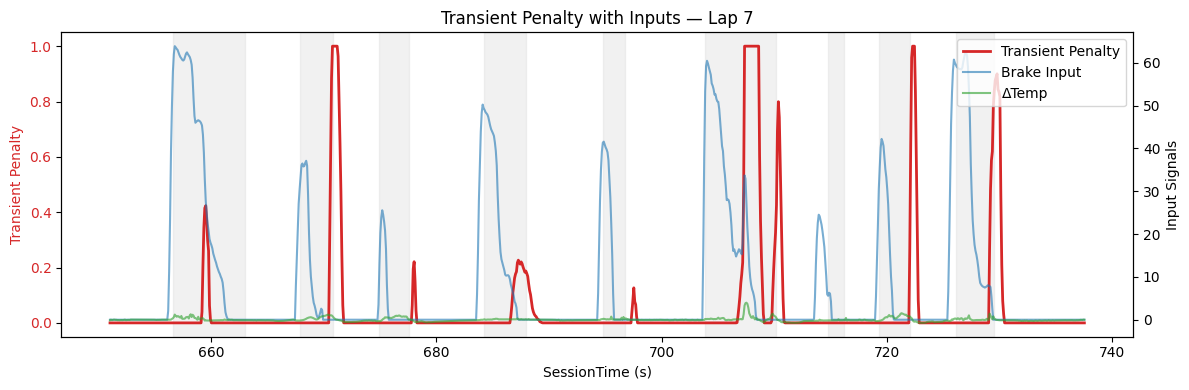

In [21]:

df1["dT_dt"] = df1["LFtempM"].diff()
lap_df = df1[df1["Lap"] == lap].copy()


# Create a multi-axis plot
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.set_title(f"Transient Penalty with Inputs — Lap {lap}")
ax1.set_xlabel("SessionTime (s)")

# Plot Transient Penalty
ax1.plot(lap_df["SessionTime"], lap_df["transient_penalty"], label="Transient Penalty", color="tab:red", linewidth=2)
ax1.set_ylabel("Transient Penalty", color="tab:red")
ax1.tick_params(axis='y', labelcolor="tab:red")

# Add shaded turns
lap_df["in_turn"] = lap_df["Turn"].notna()
in_turn_mask = lap_df["in_turn"].astype(int).diff().fillna(0)

for idx in lap_df.index:
    if in_turn_mask.loc[idx] == 1:
        start_time = lap_df.at[idx, "SessionTime"]
    elif in_turn_mask.loc[idx] == -1:
        end_time = lap_df.at[idx, "SessionTime"]
        ax1.axvspan(start_time, end_time, color="lightgray", alpha=0.3)

if lap_df["in_turn"].iloc[-1] and in_turn_mask.iloc[-1] == 0:
    ax1.axvspan(start_time, lap_df["SessionTime"].iloc[-1], color="lightgray", alpha=0.3)

# Second Y-axis for inputs
ax2 = ax1.twinx()
ax2.plot(lap_df["SessionTime"], lap_df["Brake"], label="Brake Input", color="tab:blue", alpha=0.6)
ax2.plot(lap_df["SessionTime"], lap_df["dT_dt"], label="ΔTemp", color="tab:green", alpha=0.6)
ax2.set_ylabel("Input Signals")
ax2.tick_params(axis='y')

# Add legends
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right")

plt.tight_layout()
plt.show()


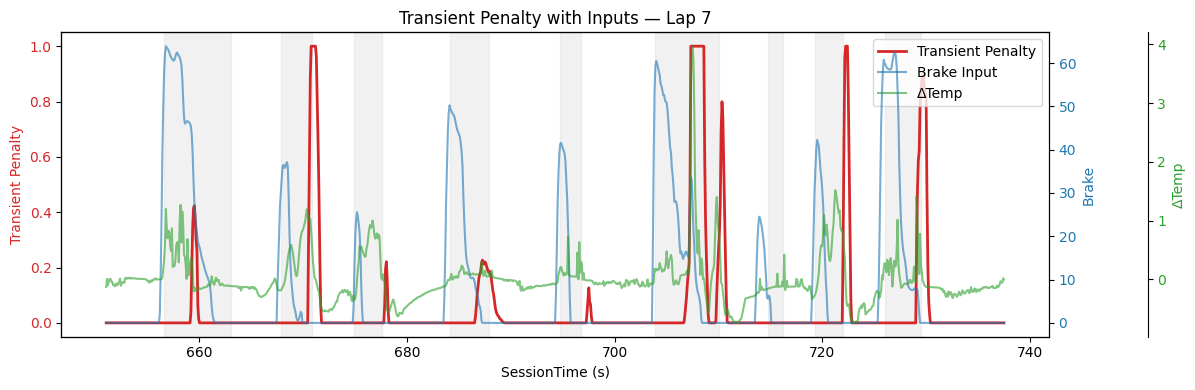

In [23]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.set_title(f"Transient Penalty with Inputs — Lap {lap}")
ax1.set_xlabel("SessionTime (s)")

# Plot Transient Penalty (primary axis)
ax1.plot(lap_df["SessionTime"], lap_df["transient_penalty"], label="Transient Penalty", color="tab:red", linewidth=2)
ax1.set_ylabel("Transient Penalty", color="tab:red")
ax1.tick_params(axis='y', labelcolor="tab:red")

# Shaded turn regions
lap_df["in_turn"] = lap_df["Turn"].notna()
in_turn_mask = lap_df["in_turn"].astype(int).diff().fillna(0)

for idx in lap_df.index:
    if in_turn_mask.loc[idx] == 1:
        start_time = lap_df.at[idx, "SessionTime"]
    elif in_turn_mask.loc[idx] == -1:
        end_time = lap_df.at[idx, "SessionTime"]
        ax1.axvspan(start_time, end_time, color="lightgray", alpha=0.3)

if lap_df["in_turn"].iloc[-1] and in_turn_mask.iloc[-1] == 0:
    ax1.axvspan(start_time, lap_df["SessionTime"].iloc[-1], color="lightgray", alpha=0.3)

# Second axis for Brake
ax2 = ax1.twinx()
ax2.plot(lap_df["SessionTime"], lap_df["Brake"], label="Brake Input", color="tab:blue", alpha=0.6)
ax2.set_ylabel("Brake", color="tab:blue")
ax2.tick_params(axis='y', labelcolor="tab:blue")

#ax2.plot(lap_df["SessionTime"], lap_df["Throttle"], label="Throttle Input", color="orange", alpha=0.6)


# Third axis for ΔTemp
ax3 = ax1.twinx()
ax3.spines["right"].set_position(("axes", 1.1))  # move to the right
ax3.plot(lap_df["SessionTime"], lap_df["dT_dt"], label="ΔTemp", color="tab:green", alpha=0.6)
ax3.set_ylabel("ΔTemp", color="tab:green")
ax3.tick_params(axis='y', labelcolor="tab:green")

# Combine legends
lines, labels = [], []
for ax in [ax1, ax2, ax3]:
    l, lb = ax.get_legend_handles_labels()
    lines += l
    labels += lb
ax1.legend(lines, labels, loc="upper right")

plt.tight_layout()
plt.show()


In [7]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import shap
import matplotlib.pyplot as plt

# Load your labeled dataset
#df = pd.read_csv("your_labeled_telemetry.csv")  # Replace with your actual file path

# --- Feature Selection ---
# Adjust to match how you named lag features
"""
lag_features = [
    "Brake", "Throttle", "SteeringWheelAngle", "LongAccel", "LatAccel", "Speed",
    "LFtempM", "RFtempM", "LRtempM", "RRtempM"
]

"""

hz = 12
window = 3 * hz  # 3 seconds
step = hz // 4   # every 0.25s

lag_features = [
    "Brake", "Throttle", "SteeringWheelAngle", "LongAccel", "LatAccel", "Speed",
    "LFtempM", "RFtempM", "LRtempM", "RRtempM"
]

# Create lagged features
for feature in lag_features:
    for lag in range(0, window + 1, step):  # 0, 3, 6, ..., 36
        df[f"{feature}_lag_{lag}"] = df[feature].shift(lag)

input_features = [col for col in df.columns if any(f in col for f in lag_features) and "lag_" in col]
target = "deg_delta_3s"

# Drop missing rows
df = df.dropna(subset=input_features + [target])

# --- Train-Test Split ---
X = df[input_features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


C:\Users\cisan\AppData\Local\Temp\ipykernel_202688\2704666568.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{feature}_lag_{lag}"] = df[feature].shift(lag)
C:\Users\cisan\AppData\Local\Temp\ipykernel_202688\2704666568.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{feature}_lag_{lag}"] = df[feature].shift(lag)
C:\Users\cisan\AppData\Local\Temp\ipykernel_202688\2704666568.py:33: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poo

In [8]:
input_features

['Brake_lag_0',
 'Brake_lag_3',
 'Brake_lag_6',
 'Brake_lag_9',
 'Brake_lag_12',
 'Brake_lag_15',
 'Brake_lag_18',
 'Brake_lag_21',
 'Brake_lag_24',
 'Brake_lag_27',
 'Brake_lag_30',
 'Brake_lag_33',
 'Brake_lag_36',
 'Throttle_lag_0',
 'Throttle_lag_3',
 'Throttle_lag_6',
 'Throttle_lag_9',
 'Throttle_lag_12',
 'Throttle_lag_15',
 'Throttle_lag_18',
 'Throttle_lag_21',
 'Throttle_lag_24',
 'Throttle_lag_27',
 'Throttle_lag_30',
 'Throttle_lag_33',
 'Throttle_lag_36',
 'SteeringWheelAngle_lag_0',
 'SteeringWheelAngle_lag_3',
 'SteeringWheelAngle_lag_6',
 'SteeringWheelAngle_lag_9',
 'SteeringWheelAngle_lag_12',
 'SteeringWheelAngle_lag_15',
 'SteeringWheelAngle_lag_18',
 'SteeringWheelAngle_lag_21',
 'SteeringWheelAngle_lag_24',
 'SteeringWheelAngle_lag_27',
 'SteeringWheelAngle_lag_30',
 'SteeringWheelAngle_lag_33',
 'SteeringWheelAngle_lag_36',
 'LongAccel_lag_0',
 'LongAccel_lag_3',
 'LongAccel_lag_6',
 'LongAccel_lag_9',
 'LongAccel_lag_12',
 'LongAccel_lag_15',
 'LongAccel_lag_18'

100%|===================| 3182/3190 [05:16<00:00]        

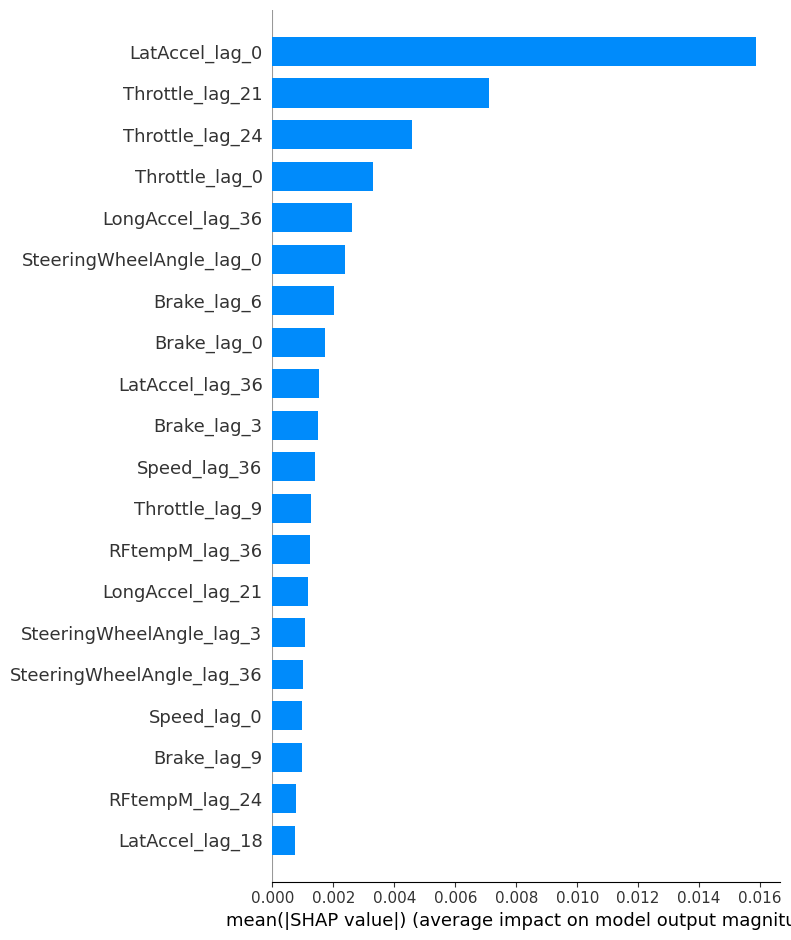

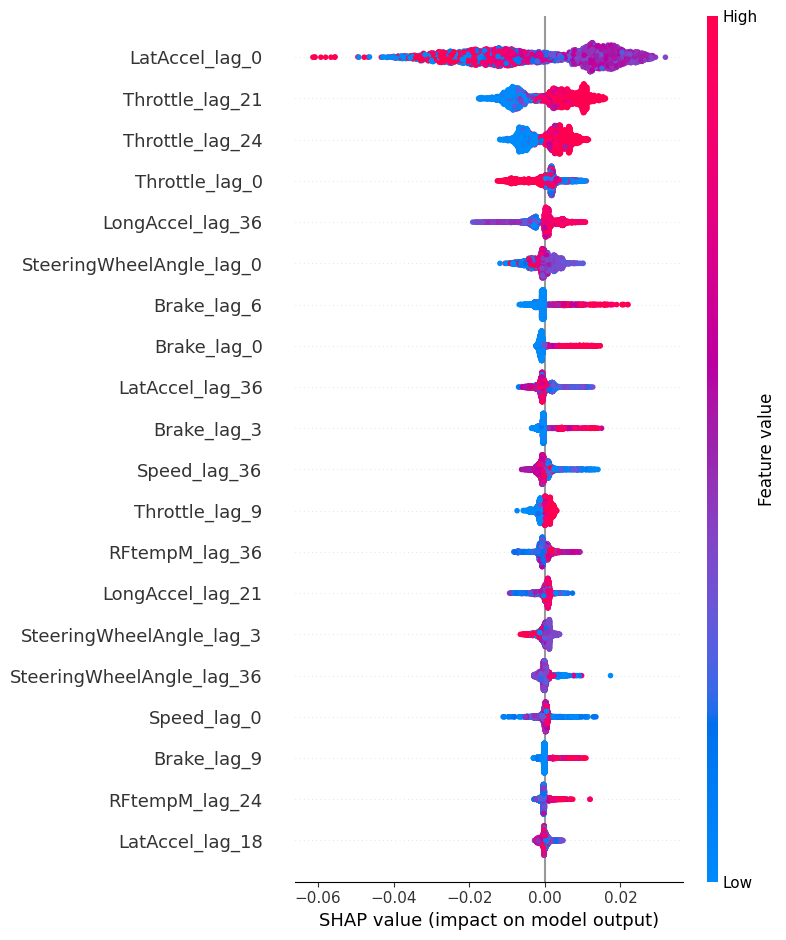

In [9]:

# --- Train Random Forest ---
model = RandomForestRegressor(
    n_estimators=200, max_depth=15, random_state=42, n_jobs=-1
)
model.fit(X_train, y_train)

# --- SHAP Analysis ---
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

# --- Plot Summary ---
shap.summary_plot(shap_values, X_test, plot_type="bar", show=True)
shap.summary_plot(shap_values, X_test, show=True)


In [26]:
lap_summary = df.groupby("Lap").agg({
    "combined_degradation": ["mean", "max"],
    "deg_delta_3s": ["mean", "max"],
    "Throttle": "mean",
    "Brake": "mean",
    "LatAccel": "mean",
    "LatG": ["mean", "max"],
    "LongAccel": "mean",
    "Speed": "mean"
})

# Flatten column names
lap_summary.columns = ['_'.join(col).strip() for col in lap_summary.columns.values]

# Compute LapTime = max(SessionTime) - min(SessionTime) per lap
lap_times = df.groupby("Lap")["SessionTime"].agg(["min", "max"])
lap_times["LapTime"] = lap_times["max"] - lap_times["min"]

# Merge LapTime into existing lap_summary
lap_summary = lap_summary.merge(lap_times["LapTime"], left_on="Lap", right_index=True)

lap_summary = lap_summary.reset_index()

lap_summary.head(n=15)


,Lap,combined_degradation_mean,combined_degradation_max,deg_delta_3s_mean,deg_delta_3s_max,Throttle_mean,Brake_mean,LatAccel_mean,LatG_mean,LatG_max,LongAccel_mean,Speed_mean,LapTime
0,1,0.054853,0.171946,-0.000005,0.151204,61.261386,8.294044,0.173225,0.771773,2.42437,-0.013605,40.184627,88.750000
1,2,0.056672,0.187722,0.000029,0.166440,63.124332,8.418074,0.176383,0.803670,2.91800,-0.008919,40.867564,87.150000
2,3,0.058394,0.193206,-0.000010,0.183307,63.605551,8.501601,0.186122,0.839539,3.14058,-0.007255,41.313928,86.100000
3,4,0.056649,0.195624,-0.000161,0.178607,62.783142,8.262575,0.196678,0.814584,3.20718,-0.004517,41.029940,86.666667
4,5,0.058017,0.186067,0.000247,0.183186,62.256308,8.225153,0.178493,0.836077,3.00138,-0.011566,40.688692,87.566667
5,6,0.056373,0.190869,-0.000136,0.181925,62.754041,8.157184,0.184355,0.809923,3.24793,-0.008800,41.159838,86.433333
6,7,0.057248,0.192349,0.000014,0.174338,63.692427,8.461483,0.183875,0.816831,3.32782,-0.009179,41.239835,86.500000
7,8,0.056045,0.188214,0.000092,0.170286,62.956281,8.227870,0.184502,0.803962,3.12967,-0.006252,40.979453,86.916667
8,9,0.148271,0.294320,0.003391,0.180450,59.660154,7.029491,0.166375,0.766961,3.13319,0.013443,38.939801,91.750000
9,10,0.166112,0.309126,0.000045,0.190770,62.744212,8.139646,0.182062,0.822626,3.18779,-0.008835,41.292451,86.083333


<Axes: title={'center': 'Avg Future Degradation per Lap'}, xlabel='Lap'>

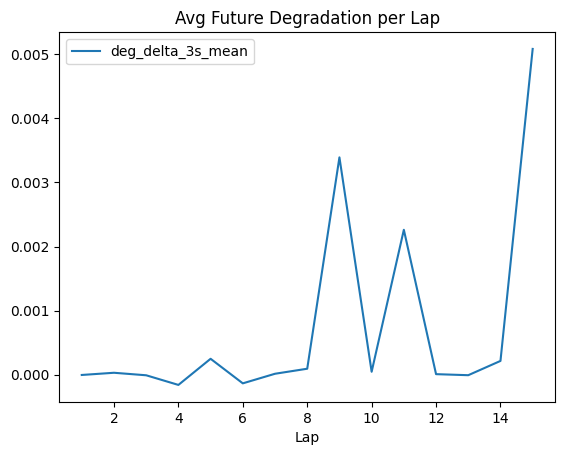

In [20]:
lap_summary.plot(x="Lap", y="deg_delta_3s_mean", title="Avg Future Degradation per Lap")


In [21]:
lap_summary.corr()["deg_delta_3s_mean"].sort_values(ascending=False)


deg_delta_3s_mean            1.000000
LongAccel_mean               0.906001
deg_delta_3s_max             0.768505
combined_degradation_max     0.756342
combined_degradation_mean    0.552268
Lap                          0.480416
Brake_mean                  -0.498465
Throttle_mean               -0.768978
LatAccel_mean               -0.851592
Speed_mean                  -0.862284
Name: deg_delta_3s_mean, dtype: float64

In [28]:
lap_summary.sort_values("deg_delta_3s_max", ascending=False).head(n=20)

lap_summary.to_csv('lap_summary.csv')


In [3]:
features = [
    "Brake", "Throttle", "Speed", "LatAccel", "LongAccel",
    "LFtempM", "LFpressure", "SteeringWheelAngle", "LFshockDefl"
    , "RFtempM", "RFpressure", "SteeringWheelAngle", "RFshockDefl"
]

X = df[features].fillna(0)
y = df["deg_delta_3s"].fillna(0)

In [33]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
#import shap

# Split and train model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=10, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("R^2 Score:", r2_score(y_test, y_pred))

R^2 Score: 0.8069740135876421


R² Score: 0.9966466178335944


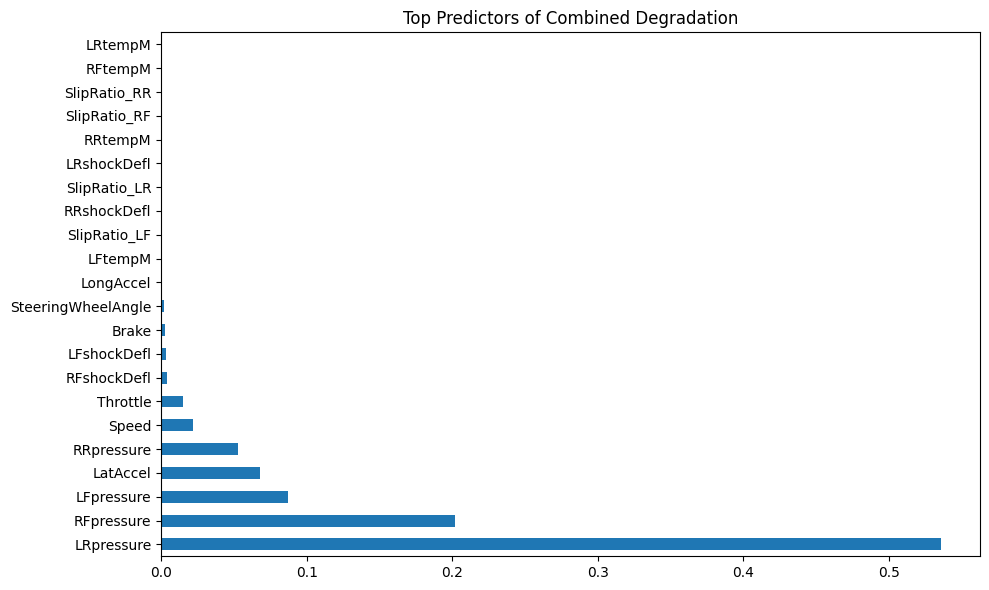

In [34]:
features = [
    "Brake", "Throttle", "SteeringWheelAngle",
    "LatAccel", "LongAccel",
    "LFtempM", "RFtempM", "LRtempM", "RRtempM",
    "LFpressure", "RFpressure", "LRpressure", "RRpressure",
    "LFshockDefl", "RFshockDefl", "LRshockDefl", "RRshockDefl",
    "SlipRatio_LF", "SlipRatio_RF", "SlipRatio_LR", "SlipRatio_RR",
    "Speed"
]

X = df[features].fillna(0)
y = df["combined_degradation"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
print("R² Score:", r2_score(y_test, y_pred))

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.plot(kind="barh", title="Top Predictors of Combined Degradation", figsize=(10,6))
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import numpy as np
import matplotlib.pyplot as plt


In [12]:

# Load dataset with multiple stints (source_file identifies stint)
df = pd.read_parquet("parquet_files\\master_12hz_5stints.parquet")

from deg_labels_v30 import compute_degradation_features

df = compute_degradation_features(df)

df.head()


,AirDensity,AirPressure,AirTemp,Alt,Brake,BrakeABSactive,BrakeABScutPct,BrakeRaw,CFSRrideHeight,Clutch,...,load_LR,load_RR,slip_power,T_core,frictional_penalty,vulcanisation_penalty,asymmetric_penalty,transient_penalty,combined_degradation,deg_delta_3s
0,1.16742,98739.6,19.6992,228.135,0.0,0,100.0,0.0,0.050589,100.0,...,0.035585,0.036753,0.256099,41.328725,0.000081,0.0,0.060174,0.0,0.012063,0.013999
1,1.16742,98739.6,19.6992,228.235,0.0,0,100.0,0.0,0.053297,100.0,...,0.037321,0.038574,0.224310,41.281075,0.000071,0.0,0.119361,-0.0,0.023897,0.001958
2,1.16742,98739.6,19.6992,228.435,0.0,0,100.0,0.0,0.049328,100.0,...,0.037448,0.039148,0.219371,41.234200,0.000069,0.0,0.121096,-0.0,0.024243,0.014824
3,1.16742,98739.6,19.6992,228.635,0.0,0,100.0,0.0,0.058073,100.0,...,0.039498,0.041732,0.181244,41.185925,0.000057,0.0,0.126456,-0.0,0.025311,0.007716
4,1.16742,98739.6,19.6992,228.835,0.0,0,100.0,0.0,0.067351,100.0,...,0.036713,0.038567,0.230397,41.137325,0.000073,0.0,0.093175,-0.0,0.018661,0.027523


In [13]:
df["source_file"].unique()

array(['porsche992cup_lagunaseca 2025-06-17 10-52-45_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-16 21-04-27_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-17 21-37-16_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-18 11-58-07_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-17 20-32-09_Stint_1.csv'],
      dtype=object)

Stint porsche992cup_lagunaseca 2025-06-17 10-52-45_Stint_1.csv R²: 0.8539
Stint porsche992cup_lagunaseca 2025-06-16 21-04-27_Stint_1.csv R²: 0.8412
Stint porsche992cup_lagunaseca 2025-06-17 21-37-16_Stint_1.csv R²: 0.8571
Stint porsche992cup_lagunaseca 2025-06-18 11-58-07_Stint_1.csv R²: 0.8579
Stint porsche992cup_lagunaseca 2025-06-17 20-32-09_Stint_1.csv R²: 0.2084

Mean R² across stints: 0.7237115226585553


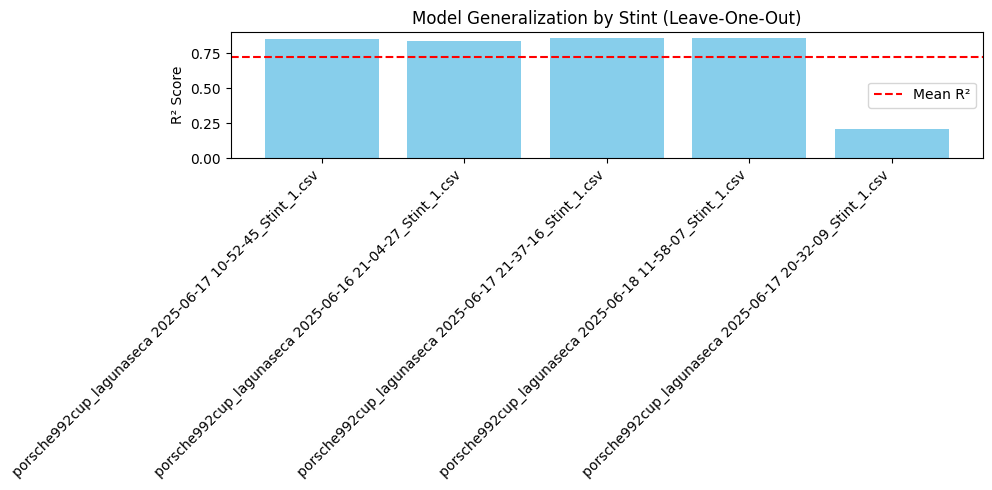

In [14]:

# Feature list
features = [
    "Brake", "Throttle", "SteeringWheelAngle",
    "LatAccel", "LongAccel",
    "LFtempM", "RFtempM", "LRtempM", "RRtempM",
    "LFpressure", "RFpressure", "LRpressure", "RRpressure",
    "LFshockDefl", "RFshockDefl", "LRshockDefl", "RRshockDefl",
    "SlipRatio_LF", "SlipRatio_RF", "SlipRatio_LR", "SlipRatio_RR",
    "Speed"
]

y_label = 'deg_delta_3s'

"""
features = [
    'LatG'
    ,'AirPressure'
,'WindDir'
,'AirDensity'
,'OilTemp'
,'SteeringWheelPctTorque'
,'Lap'
,'VelocityX'
,'LRspeed'
,'Speed'
,'RFspeed'
,'LFspeed'
,'RRspeed'
,'SessionTime'
,'FuelLevelPct'
,'FuelUsePerHour'
,'RPM'
,'RelativeHumidity'
,'RFtempM'
,'Throttle'
,'Pitch'
,'LFtempCM'
,'RFTempSpread'
,'LRtempCM'
,'Gear'
,'RFFx'
,'RRFx'
,'CFSRrideHeight'
,'PitchRate'
,'LRFx'
,'LFFx'
,'load_LR'
,'LRshockDefl'
,'VertAccel'
,'RRtempM'
,'LRrideHeight'
,'LFTempSpread'
,'RFrideHeight'
,'RFpressure'
,'load_RF'
,'RFshockDefl'
,'LapBestLapTime'
,'LFtempM'
,'LRtempM'
,'RRpressure'
,'SteeringWheelAngle'
,'YawRate'
,'LFrideHeight'
,'RRrideHeight'
,'SteeringWheelTorque_ST'
]
"""

# Store R² scores by stint
results = []

# Loop through each stint (source_file)
for stint_id in df["source_file"].unique():
    df_train = df[df["source_file"] != stint_id]
    df_test = df[df["source_file"] == stint_id]

    

    X_train = df_train[features].fillna(0)
    y_train = df_train[y_label]
    X_test = df_test[features].fillna(0)
    y_test = df_test[y_label]

    # Train model
    model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    score = r2_score(y_test, y_pred)
    results.append((stint_id, score))
    print(f"Stint {stint_id} R²: {score:.4f}")

# Summary
results_df = pd.DataFrame(results, columns=["source_file", "R2"])
print("\nMean R² across stints:", results_df["R2"].mean())

# Optional: plot R² by stint
plt.figure(figsize=(10, 5))
plt.bar(results_df["source_file"], results_df["R2"], color="skyblue")
plt.axhline(results_df["R2"].mean(), color="red", linestyle="--", label="Mean R²")
plt.xticks(rotation=45, ha="right")
plt.ylabel("R² Score")
plt.title("Model Generalization by Stint (Leave-One-Out)")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
parquet_name = "master_12hz_1stint.csv" # "master_12hz_5laps.parquet"
print(parquet_name)

#df = pd.read_parquet(f"parquet_files\\{parquet_name}")
df = pd.read_csv(f"parquet_files\\{parquet_name}")
df = compute_degradation_features(df)

# ----------------------------------------
# Purpose:
# Use SHAP to identify which future lags of driver inputs
# most strongly contribute to predicting degradation
# ----------------------------------------

# Define the input signals and lags to examine
input_signals = ["Brake", "Throttle", "LatAccel"]
lags = list(range(0, 37))  # 0 to 3 seconds at 12 Hz

# Efficiently create lagged features using concat
lagged_dfs = []
for col in input_signals:
    lagged = pd.concat(
        {f"{col}_t{lag}": df[col].shift(-lag) for lag in lags},
        axis=1
    )
    lagged_dfs.append(lagged)

lagged_df = pd.concat(lagged_dfs, axis=1)

# Target: combined_degradation 3 seconds later (aligning with input max lag)
df["target"] = df["combined_degradation"].shift(-max(lags))
df_model = pd.concat([lagged_df, df["target"]], axis=1).dropna()

X = df_model.drop(columns="target")
y = df_model["target"]

# Train Random Forest model
model = RandomForestRegressor(n_estimators=50, random_state=42)
model.fit(X, y)


master_12hz_1stint.csv


NameError: name 'shap' is not defined

In [ ]:
import shap

# Compute SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

# Plot SHAP importance by lag for each input
plt.figure(figsize=(12, 6))
for signal in input_signals:
    signal_cols = [f"{signal}_t{lag}" for lag in lags]
    signal_indices = [X.columns.get_loc(c) for c in signal_cols]
    mean_shap = np.abs(shap_values[:, signal_indices]).mean(axis=0)
    plt.plot(np.array(lags) / 12.0, mean_shap, label=signal)

plt.title("SHAP Importance vs Lag")
plt.xlabel("Lag (seconds)")
plt.ylabel("Mean |SHAP value|")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



g:\My Drive\Georgia Tech\2025 Practicum\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


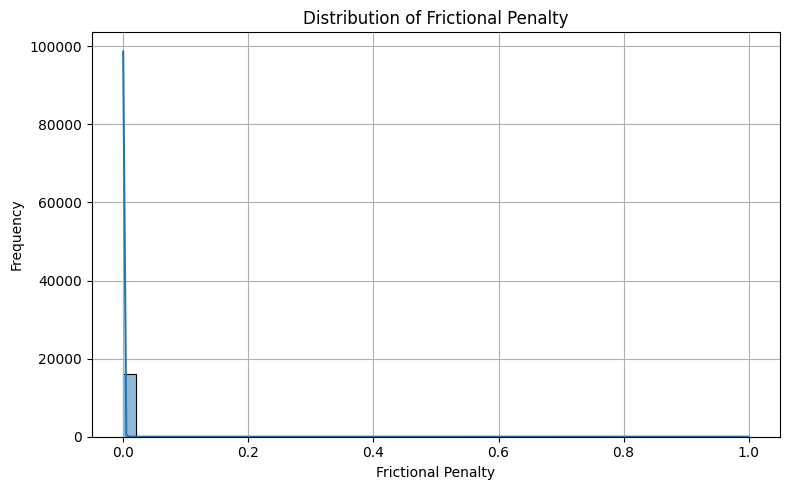

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["frictional_penalty"], bins=50, kde=True)
plt.title("Distribution of Frictional Penalty")
plt.xlabel("Frictional Penalty")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

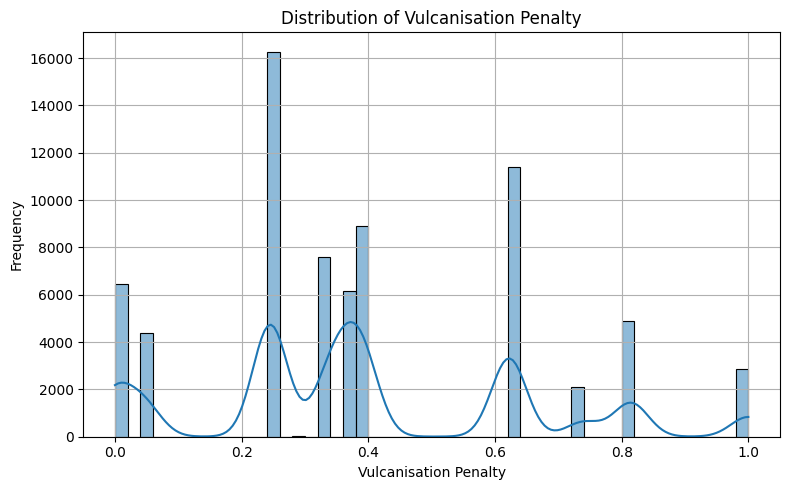

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["vulcanisation_penalty"], bins=50, kde=True)
plt.title("Distribution of Vulcanisation Penalty")
plt.xlabel("Vulcanisation Penalty")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

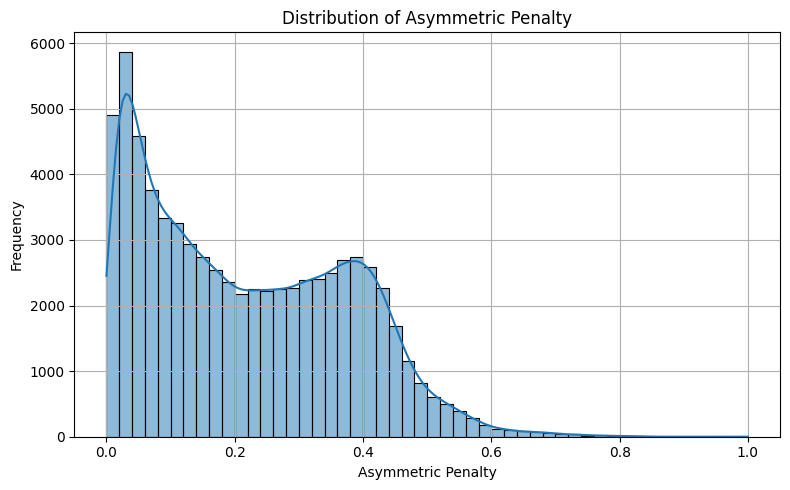

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["asymmetric_penalty"], bins=50, kde=True)
plt.title("Distribution of Asymmetric Penalty")
plt.xlabel("Asymmetric Penalty")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

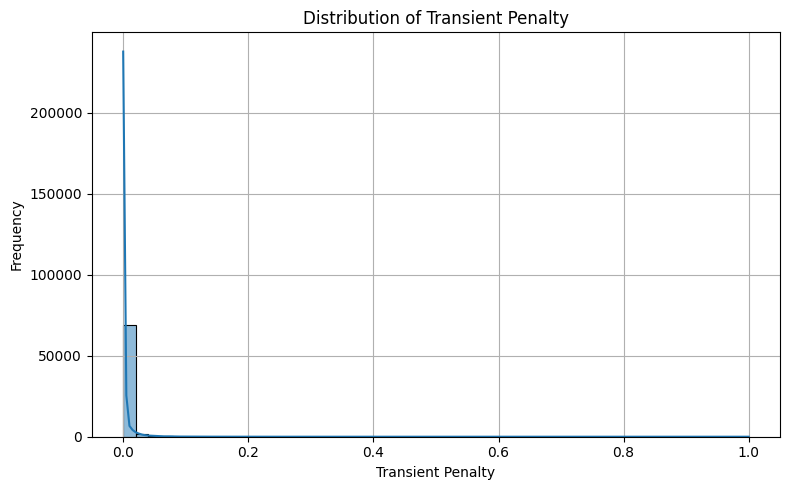

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["transient_penalty"], bins=50, kde=True)
plt.title("Distribution of Transient Penalty")
plt.xlabel("Transient Penalty")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

## Step 3: Degradation Over Laps

Visualize how degradation evolves over laps.


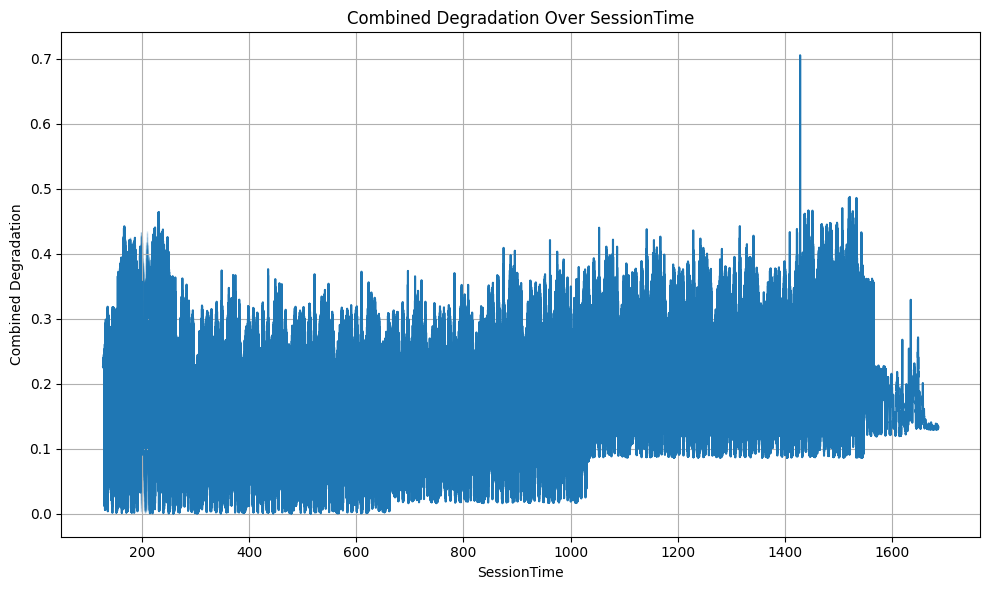

In [59]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="SessionTime", y="combined_degradation")
plt.title("Combined Degradation Over SessionTime")
plt.xlabel("SessionTime")
plt.ylabel("Combined Degradation")
plt.grid(True)
plt.tight_layout()
plt.show()

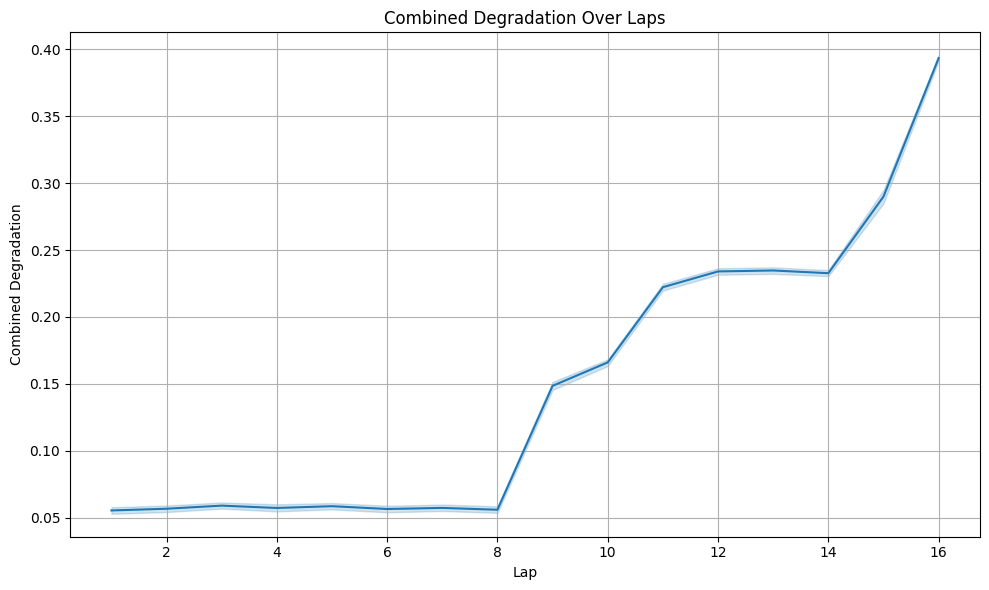

In [39]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="Lap", y="combined_degradation")
plt.title("Combined Degradation Over Laps")
plt.xlabel("Lap")
plt.ylabel("Combined Degradation")
plt.grid(True)
plt.tight_layout()
plt.show()

## Step 4: Correlation Matrix

Explore how telemetry features relate to degradation.


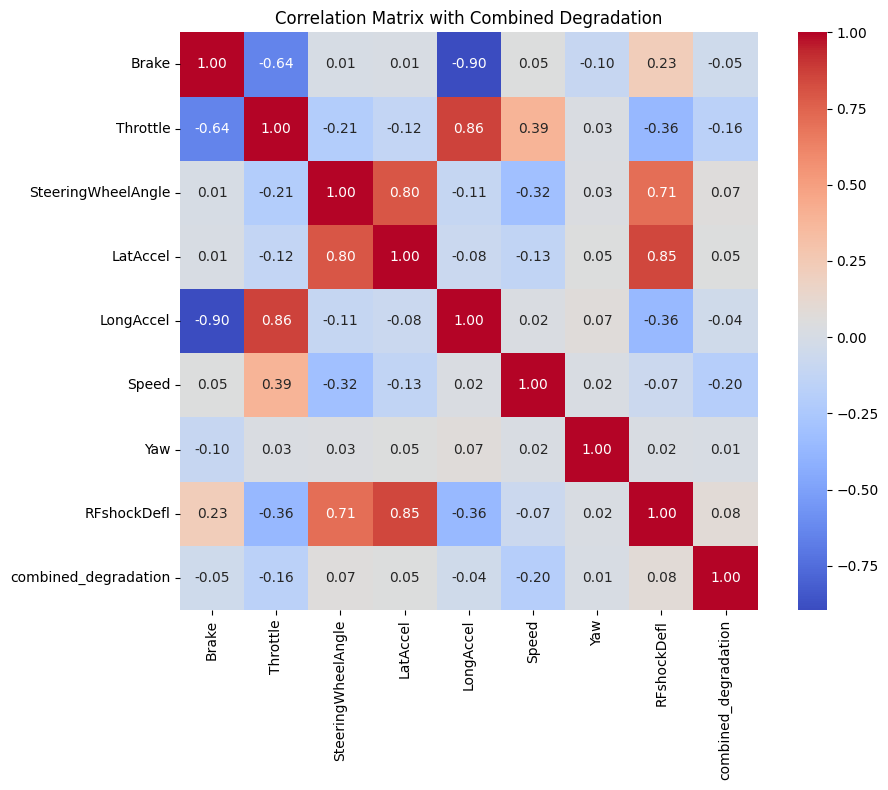

In [61]:
telemetry_vars = ["Brake", "Throttle", "SteeringWheelAngle", "LatAccel", "LongAccel", "Speed", "Yaw", "RFshockDefl"]

corr = df[telemetry_vars + ["combined_degradation"]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix with Combined Degradation")
plt.tight_layout()
plt.show()

## Step 5: Behavioral Inputs vs. Degradation

Compare behavioral telemetry inputs with degradation values.


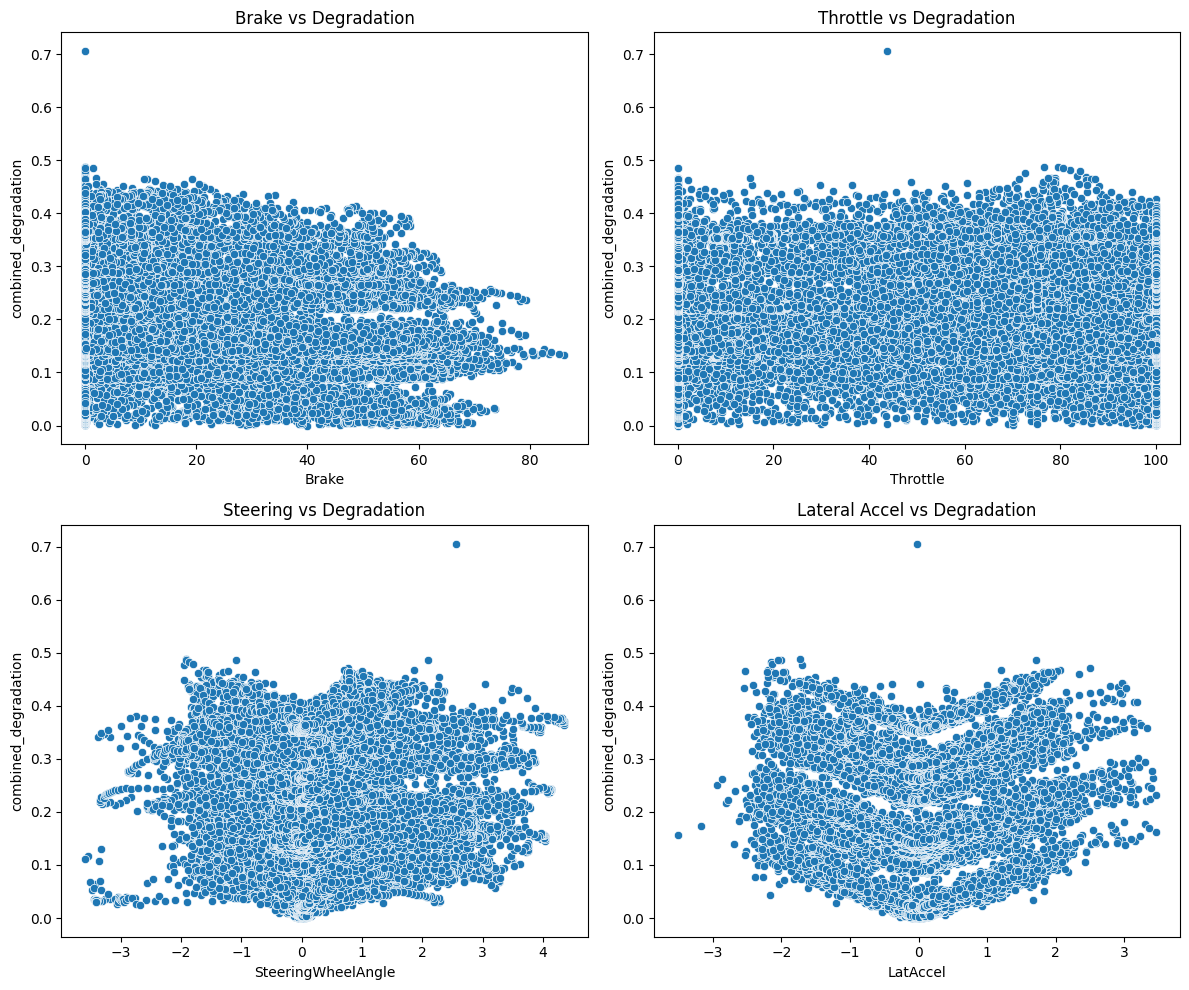

In [63]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

sns.scatterplot(data=df, x="Brake", y="combined_degradation", ax=axs[0, 0])
axs[0, 0].set_title("Brake vs Degradation")

sns.scatterplot(data=df, x="Throttle", y="combined_degradation", ax=axs[0, 1])
axs[0, 1].set_title("Throttle vs Degradation")

sns.scatterplot(data=df, x="SteeringWheelAngle", y="combined_degradation", ax=axs[1, 0])
axs[1, 0].set_title("Steering vs Degradation")

sns.scatterplot(data=df, x="LatAccel", y="combined_degradation", ax=axs[1, 1])
axs[1, 1].set_title("Lateral Accel vs Degradation")

plt.tight_layout()
plt.show()

## Step 6 (Optional): Degradation by Turn

If the dataset includes a `Turn` column, we can evaluate whether some corners are more degrading than others.


In [64]:
if "Turn" in df.columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x="Turn", y="combined_degradation")
    plt.title("Degradation by Turn")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

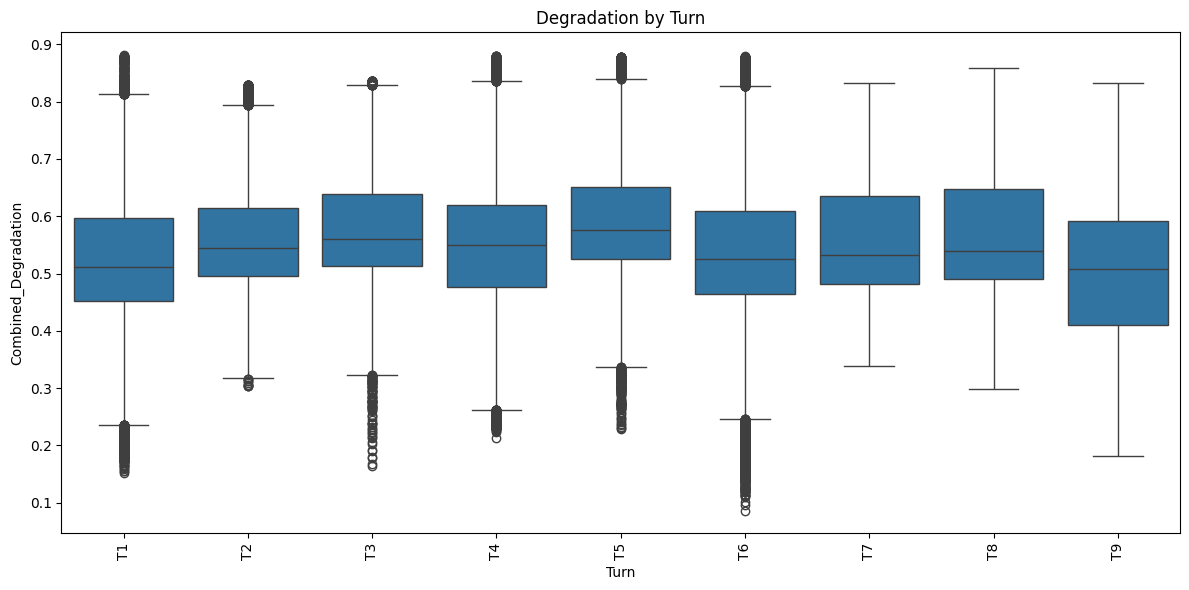

In [ ]:
if "Turn" in df.columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x="Turn", y="combined_degradation")
    plt.title("Degradation by Turn")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

## Step 7: Input Traces

Plot traces over distance


15 laps


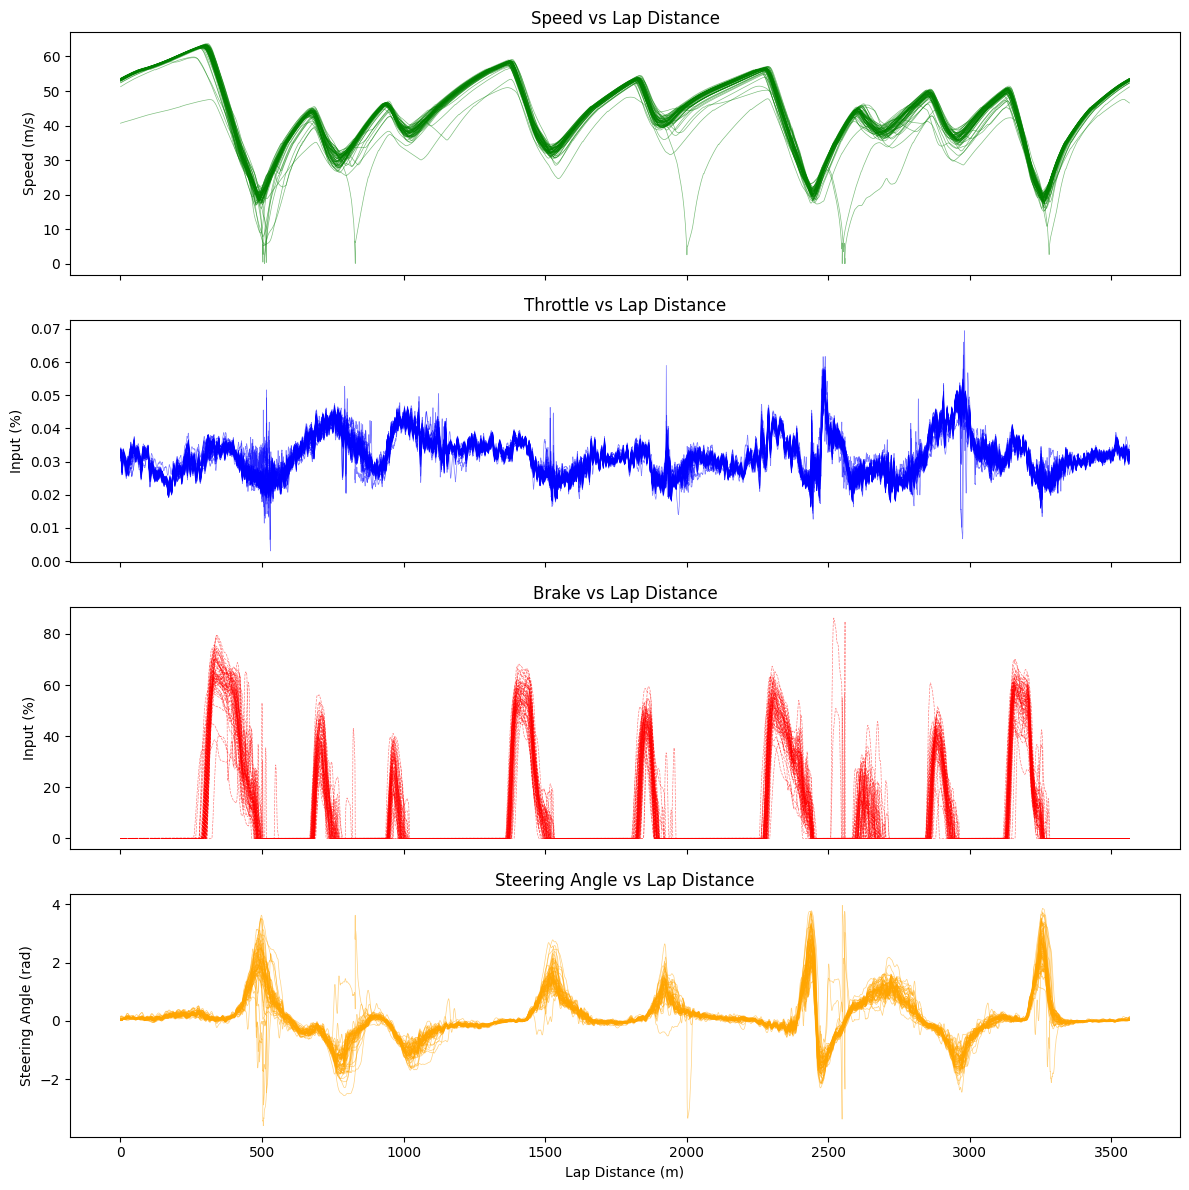

In [14]:
import numpy as np

# PLOTS OF THROTTLE, BRAKE, SPEED AND STEERING ANGLE

laps_to_plot = np.arange(1,16)
print(f"{len(laps_to_plot)} laps")
src_file_nm = 'porsche992cup_lagunaseca 2025-06-18 11-58-07_Stint_1.csv'
#df_p = df[(df["Lap"].isin(laps_to_plot)) & (df['source_file'] == src_file_nm)]
df_p = df[(df["Lap"].isin(laps_to_plot))]

#df_p = df[(df["Lap"].isin(laps_to_plot)) & (df['source_file'] == src_file_nm) & (df['LapDist'] >= 1000) & (df['LapDist'] <= 1400)]

# Create overlay plots
fig, axs = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

for stint_num, stint_df in df_p.groupby("source_file"):
    for lap_num, lap_df in stint_df.groupby("Lap"):
        axs[0].plot(lap_df["LapDist"], lap_df["Speed"], color="green", alpha=0.5, linewidth=0.5)
        #axs[1].plot(lap_df["LapDist"], lap_df["Throttle"], label="Throttle (%)", color="blue", alpha=0.5, linewidth=0.5)
        axs[1].plot(lap_df["LapDist"], lap_df["LFshockDefl"], label="Throttle (%)", color="blue", alpha=0.5, linewidth=0.5)
        
        axs[2].plot(lap_df["LapDist"], lap_df["Brake"], color="red", alpha=0.5, linewidth=0.5, label="Brake (%)", linestyle="--")
        axs[3].plot(lap_df["LapDist"], lap_df["SteeringWheelAngle"], color="orange", alpha=0.5, linewidth=0.5)

# Define corner locations and names
turns = {
    100: "T1",
    300: "T2",
    480: "T3",
    620: "T4",
    740: "T5",
    880: "T6",
    1000: "T7",
    1070: "T8 (Corkscrew)",
    1150: "T9",
    1250: "T10",
    1350: "T11"
}

#for dist, name in turns.items():
    #axs[0].axvline(x=dist, color='gray', linestyle='--', alpha=0.5)
    #axs[0].text(dist + 5, max(lap_df["Speed"])*0.9, name, rotation=90, fontsize=8)



# Speed
axs[0].set_ylabel("Speed (m/s)")
axs[0].set_title("Speed vs Lap Distance")

# Throttle
axs[1].set_ylabel("Input (%)")
axs[1].set_title("Throttle vs Lap Distance")

# Brake
#axs[1].plot(df_p["LapDist (m)"], df_p["Brake (%)"], label="Brake (%)", linestyle="--")
axs[2].set_ylabel("Input (%)")
axs[2].set_title("Brake vs Lap Distance")
#axs[1].legend()

# Steering
axs[3].set_ylabel("Steering Angle (rad)")
axs[3].set_xlabel("Lap Distance (m)")
axs[3].set_title("Steering Angle vs Lap Distance")

plt.tight_layout()
plt.show()

## Input Traces

Plot traces over distance


In [15]:
df['source_file'].unique()

array(['porsche992cup_lagunaseca 2025-06-17 10-52-45_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-16 21-04-27_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-17 21-37-16_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-18 11-58-07_Stint_1.csv',
       'porsche992cup_lagunaseca 2025-06-17 20-32-09_Stint_1.csv'],
      dtype=object)

C:\Users\cisan\AppData\Local\Temp\ipykernel_16792\3340318534.py:27: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=turn_lap_summary, x="Lap", y="LatG", hue="Turn", ci=None, marker='o')


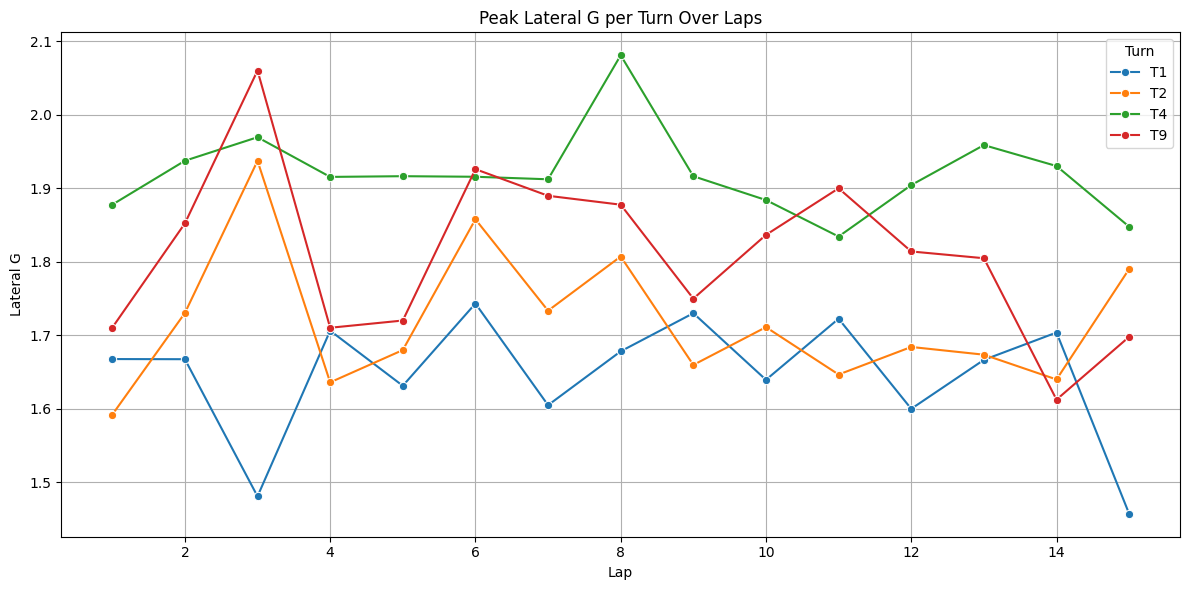

In [17]:
#df["LatG"] = df["LatAccel"].abs()

src_file_list = [
'porsche992cup_lagunaseca 2025-06-17 10-52-45_Stint_1.csv',
'porsche992cup_lagunaseca 2025-06-16 21-04-27_Stint_1.csv',
'porsche992cup_lagunaseca 2025-06-17 21-37-16_Stint_1.csv',
'porsche992cup_lagunaseca 2025-06-18 11-58-07_Stint_1.csv',
'porsche992cup_lagunaseca 2025-06-17 20-32-09_Stint_1.csv'
]

turns_list = [
    'T1'
    , 'T2'
    #, 'T3'
    , 'T4', 'T9'
]

turn_lap_summary = df[(df['source_file'].isin(src_file_list)) & (df['Turn'].isin(turns_list)) & (df['Lap'] < 16)].groupby(["source_file", "Lap", "Turn"]).agg({
    "LatG": "max",  # or .mean if preferred
    "combined_degradation": "mean"
}).reset_index()

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.lineplot(data=turn_lap_summary, x="Lap", y="LatG", hue="Turn", ci=None, marker='o')
plt.title("Peak Lateral G per Turn Over Laps")
plt.ylabel("Lateral G")
plt.xlabel("Lap")
plt.grid(True)
plt.tight_layout()
plt.show()

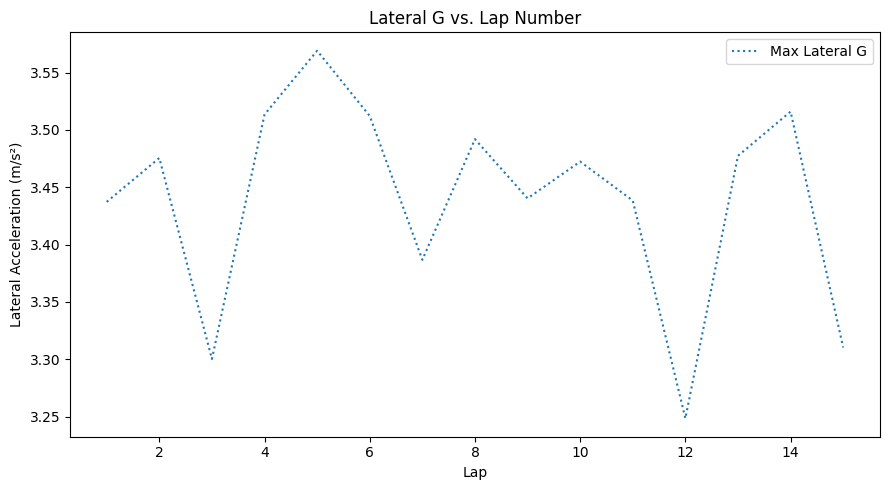

In [18]:
# LATERAL G BY LAP

# Aggregate mean and/or max lateral G by lap
g_summary = df_p.groupby("Lap")["LatAccel"].agg(['mean', 'max']).reset_index()

# Plot
plt.figure(figsize=(9, 5))
#plt.plot(g_summary["Lap"], g_summary["mean"], label="Mean Lateral G")
plt.plot(g_summary["Lap"], g_summary["max"], label="Max Lateral G", linestyle=":")
plt.xlabel("Lap")
plt.ylabel("Lateral Acceleration (m/s²)")
plt.title("Lateral G vs. Lap Number")
#plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

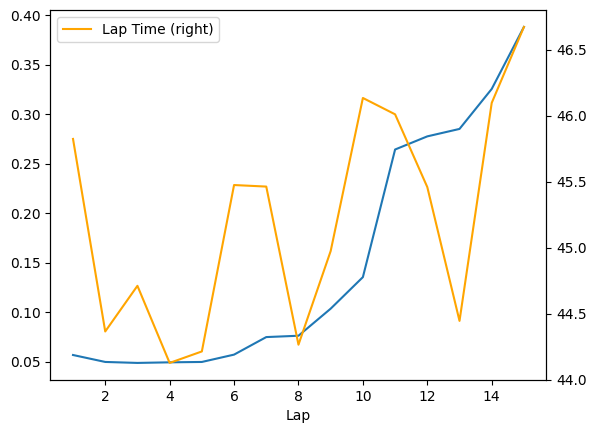

In [19]:
laps_to_plot = np.arange(1,16)
#df_p = df[(df["Lap"].isin(laps_to_plot)) & (df['source_file'] == src_file_nm)]
df_p = df[(df["Lap"].isin(laps_to_plot))]

df_p.groupby("Lap")["combined_degradation"].mean().plot(label="Degradation")
df_p.groupby("Lap")["LapCurrentLapTime"].mean().plot(secondary_y=True, label="Lap Time", color="orange")
plt.legend()

In [69]:
EPSILON = 1e-3  # to avoid divide-by-zero

for corner in ['LF', 'RF', 'LR', 'RR']:
    wheel_col = f"{corner}speed"
    df[f"SlipRatio_{corner}"] = (df[wheel_col] - df["Speed"]) / df["Speed"].clip(lower=EPSILON)

# Drop NA for the target
df = df.dropna(subset=["combined_degradation"])

for tire in ["LF", "RF", "LR", "RR"]:
    df[f"{tire}TempSpread"] = df[[f"{tire}tempL", f"{tire}tempM", f"{tire}tempR"]].max(axis=1) - df[[f"{tire}tempL", f"{tire}tempM", f"{tire}tempR"]].min(axis=1)

# === STEP 1: Define columns to exclude ===
exclude_columns = [
    "combined_degradation"         # don't correlate target with itself
    #,"deg_delta"
    #,"deg_delta_smooth"
    ,"vulcanisation_penalty"
    ,"frictional_penalty"
    ,"asymmetric_penalty"
    ,"T_core"
    ,"LR_degradation", "RR_degradation", "RF_degradation", "LF_degradation", "TrackTempCrew"  # submodel outputs, already baked into label
    ,"FuelLevel"                  # duplicate of FuelLevel
    ,"BrakeRaw","ThrottleRaw","LapDist"
    , "RFtempL","RFtempR", "RRtempL","RRtempR", "LFtempL","LFtempR", "LRtempL","LRtempR"
    ,"LapCompleted", "TrackTempCrew","SteeringWheelTorque","SteeringWheelPctTorqueSign","SteeringWheelPctTorqueSignStops"
    ,"SessionTick","SessionTimeOfDay","LapBestLap"
    ,"LFtempCL","LFtempCR","RFtempCL","RFtempCR","LRtempCL","LRtempCR","RRtempCL","RRtempCR","RFtempCM","RRtempCM"
    ,"RFbrakeLinePress","RRbrakeLinePress","Engine0_RPM"
]

# === STEP 2: Filter out unwanted columns ===
numeric_cols = df.select_dtypes(include=["number"]).columns
correlation_input_cols = [col for col in numeric_cols if col not in exclude_columns]

# === STEP 3: Compute correlations ===
correlations = df[correlation_input_cols].corrwith(df["combined_degradation"])

# === STEP 4: Sort and show top results ===
top_correlations = correlations.abs().sort_values(ascending=False)
print("🔍 Top correlated features with Combined_Degradation:")
print(top_correlations.head(100))

🔍 Top correlated features with Combined_Degradation:
AirPressure          4.501703e-01
WindDir              4.189628e-01
AirDensity           4.164744e-01
OilTemp              3.159608e-01
LatG                 2.883485e-01
                         ...     
transient_penalty    7.456624e-03
RollRate             2.341227e-03
dpRFTireColdPress    2.617433e-16
dpLRTireColdPress    2.617433e-16
RFcoldPressure       2.617433e-16
Length: 100, dtype: float64


g:\My Drive\Georgia Tech\2025 Practicum\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
g:\My Drive\Georgia Tech\2025 Practicum\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [71]:
top_correlations.to_csv('top_correlations_delta.csv')
top_correlations.head(n=50)

AirPressure               0.450170
WindDir                   0.418963
AirDensity                0.416474
OilTemp                   0.315961
LatG                      0.288348
SteeringWheelPctTorque    0.276344
Lap                       0.199237
VelocityX                 0.197809
LRspeed                   0.197612
Speed                     0.197561
RFspeed                   0.197311
LFspeed                   0.197304
RRspeed                   0.196689
SessionTime               0.194848
FuelLevelPct              0.189438
FuelUsePerHour            0.175299
RPM                       0.173222
RelativeHumidity          0.170517
RFtempM                   0.168390
Throttle                  0.164871
Pitch                     0.149552
LFtempCM                  0.138333
RFTempSpread              0.136525
LRtempCM                  0.135884
Gear                      0.134447
RFFx                      0.115657
RRFx                      0.115657
CFSRrideHeight            0.115209
PitchRate           

In [65]:
# Filter numeric columns and exclude unwanted ones
numeric_cols = df.select_dtypes(include=["number"]).columns
cols_to_check = [col for col in numeric_cols if col not in exclude_columns]

# Compute full correlation matrix (absolute values)
corr_matrix = df[cols_to_check].corr().abs()

# Mask diagonal and lower triangle
mask = corr_matrix.where(~np.tril(np.ones(corr_matrix.shape)).astype(bool))

# Extract and filter strong correlation pairs
high_corr_pairs = mask.stack().reset_index()
high_corr_pairs.columns = ["Feature1", "Feature2", "Correlation"]
high_corr_pairs = high_corr_pairs[high_corr_pairs["Correlation"] > 0.98].sort_values(by="Correlation", ascending=False)

# Heatmap of top correlations (thresholded)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix.where(corr_matrix > 0.8), cmap="coolwarm", annot=False)
plt.title("Feature Correlation Heatmap (|r| > 0.8)")
plt.tight_layout()
plt.show()

# Print highly correlated feature pairs
print(high_corr_pairs.head(40))

NameError: name 'exclude_columns' is not defined

In [33]:
col_list = ['Fx_rear','Fx_front']
df[col_list].head(n=25)

grouped_counts = df.groupby(col_list).size().reset_index(name='Count')

print(grouped_counts)

            Fx_rear     Fx_front  Count
0      -1463.787031 -1064.342557      1
1      -1448.763391 -1053.418631      1
2      -1446.928688 -1052.084590      1
3      -1443.025921 -1049.246827      1
4      -1442.237321 -1048.673423      1
...             ...          ...    ...
499652   817.327899   594.291961      1
499653   820.916835   596.901533      1
499654   828.320022   602.284506      1
499655   842.868893   612.863219      1
499656   860.395133   625.606823      1

[499657 rows x 3 columns]


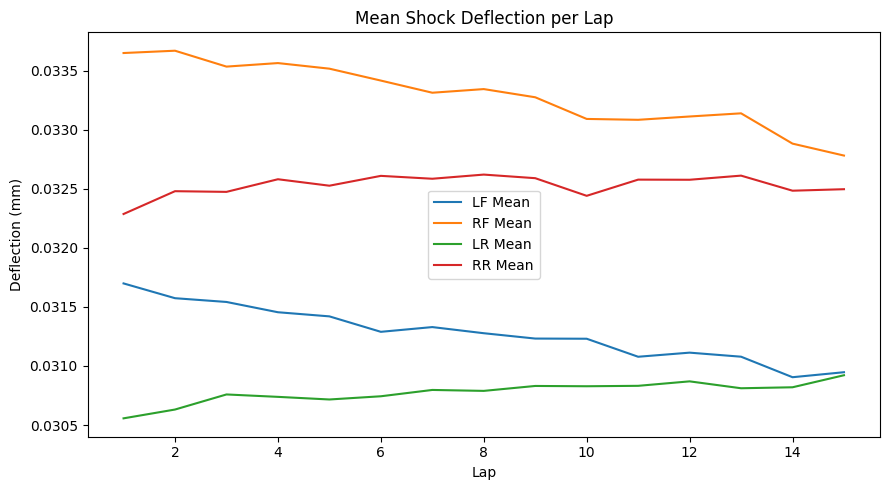

In [34]:
#Higher deflection = more compression = more load on that corner

#Lower deflection = less compression = reduced load on that corner

# indicative of Tires are losing grip (degradation), reducing front-end load during braking/turn-in.

# SHOCK DEFLECTION PER LAP

# --- Step 2: Compute per-lap mean and max shock deflection
lap_summary = df_p.groupby("Lap").agg({
    "LFshockDefl": ['mean', 'max'],
    "RFshockDefl": ['mean', 'max'],
    "LRshockDefl": ['mean', 'max'],
    "RRshockDefl": ['mean', 'max'],
})

# Flatten column names
lap_summary.columns = [f"{col[0]}_{col[1]}" for col in lap_summary.columns]
lap_summary.reset_index(inplace=True)

# --- Step 3: Plot mean deflection trends
plt.figure(figsize=(9, 5))
for corner in ['LF', 'RF', 'LR', 'RR']:
    plt.plot(lap_summary["Lap"], lap_summary[f"{corner}shockDefl_mean"], label=f"{corner} Mean")

plt.title("Mean Shock Deflection per Lap")
plt.xlabel("Lap")
plt.ylabel("Deflection (mm)")
plt.legend()
#plt.grid(True)
plt.tight_layout()
plt.show()

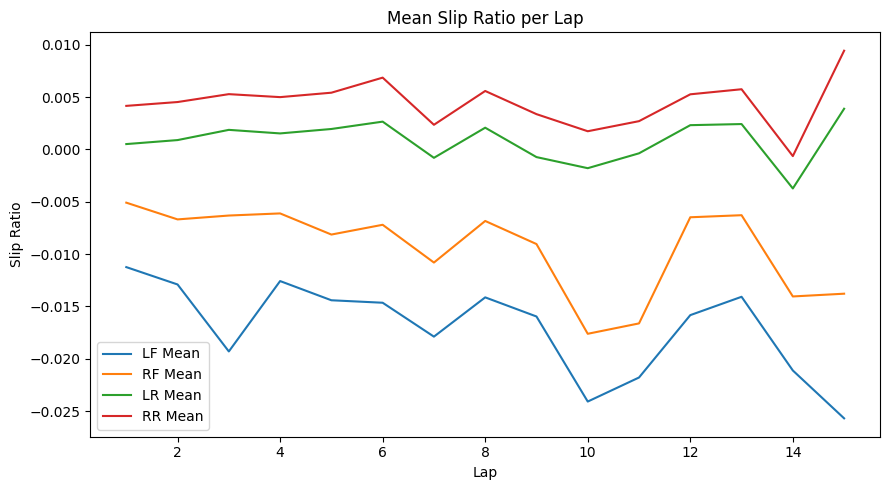

In [35]:
#Negative slip ratio → Wheel is rotating slower than the car → typically during braking.

#Positive slip ratio → Wheel is rotating faster than the car → usually during acceleration (or wheelspin).

# Front tires losing grip, causing more wheel deceleration under the same brake input.

# SHOCK DEFLECTION PER LAP

for corner in ['LF', 'RF', 'LR', 'RR']:
    wheel_col = f"{corner}speed"
    df_p[f"SlipRatio_{corner}"] = (df_p[wheel_col] - df_p["Speed"]) / df_p["Speed"].clip(lower=EPSILON)

# --- Step 2: Compute per-lap mean and max shock deflection
lap_summary = df_p.groupby("Lap").agg({
    "SlipRatio_LF": ['mean', 'max'],
    "SlipRatio_RF": ['mean', 'max'],
    "SlipRatio_LR": ['mean', 'max'],
    "SlipRatio_RR": ['mean', 'max'],
})

# Flatten column names
lap_summary.columns = [f"{col[0]}_{col[1]}" for col in lap_summary.columns]
lap_summary.reset_index(inplace=True)

# --- Step 3: Plot mean deflection trends
plt.figure(figsize=(9, 5))
for corner in ['LF', 'RF', 'LR', 'RR']:
    plt.plot(lap_summary["Lap"], lap_summary[f"SlipRatio_{corner}_mean"], label=f"{corner} Mean")

plt.title("Mean Slip Ratio per Lap")
plt.xlabel("Lap")
plt.ylabel("Slip Ratio")
plt.legend()
#plt.grid(True)
plt.tight_layout()
plt.show()

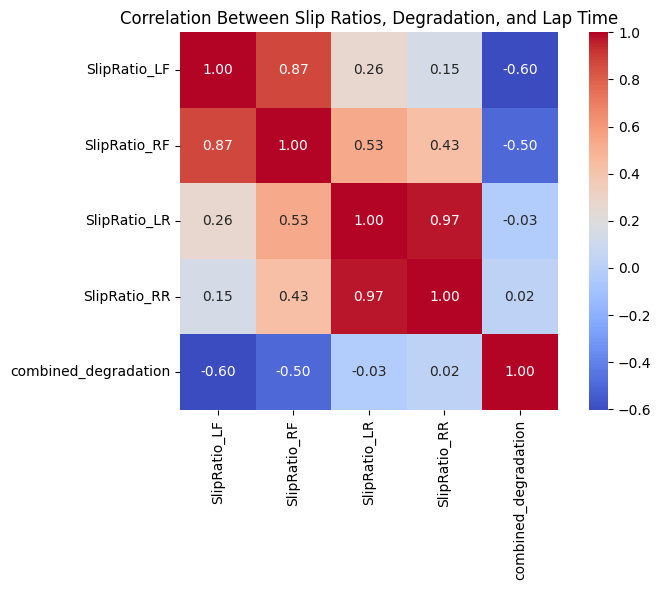

In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Group by lap and calculate mean per lap
per_lap_df = df_p.groupby("Lap").agg({
    "SlipRatio_LF": "mean",
    "SlipRatio_RF": "mean",
    "SlipRatio_LR": "mean",
    "SlipRatio_RR": "mean",
    "combined_degradation": "mean",
    #"LapTime": "mean"  # replace or compute if needed
}).reset_index()

# Step 2: Create correlation matrix
features = [
    "SlipRatio_LF", "SlipRatio_RF", "SlipRatio_LR", "SlipRatio_RR",
    "combined_degradation"#, "LapTime"
]

corr = per_lap_df[features].corr()

# Step 3: Plot
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Between Slip Ratios, Degradation, and Lap Time")
plt.tight_layout()
plt.show()


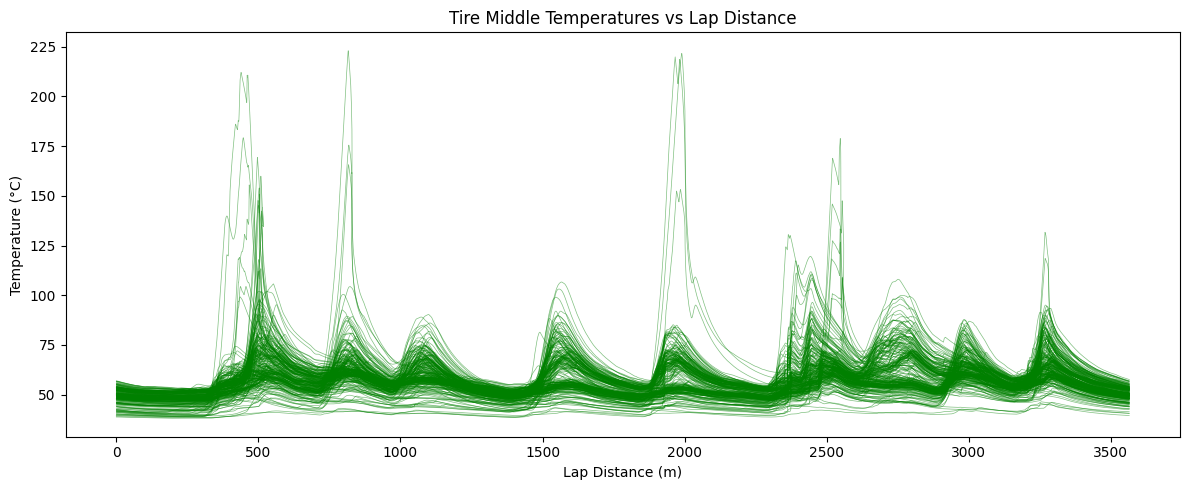

In [39]:
# Tire temperature and wear
temp_cols = ["LFtempM", "RFtempM", "LRtempM", "RRtempM"]
for col in temp_cols:
    #print(col)
    df[col] = pd.to_numeric(df[col], errors="coerce")


# Plot 4: Tire Temperatures
plt.figure(figsize=(12, 5))

for stint_num, stint_df in df_p.groupby("source_file"):
    for lap_num, lap_df in stint_df.groupby("Lap"):
        for col in temp_cols:
            plt.plot(lap_df["LapDist"], lap_df[col], label="something",color="green", alpha=0.5, linewidth=0.5)
    

# for lap_num, lap_df in df_p.groupby("Lap"):
#     for col in temp_cols:
#         plt.plot(lap_df["LapDist"], lap_df[col], label="something",color="green", alpha=0.5, linewidth=0.5)
#     #   (lap_df["LapDist (m)"], lap_df["Throttle (%)"], label="Throttle (%)", color="blue", alpha=0.5, linewidth=0.5)

plt.title("Tire Middle Temperatures vs Lap Distance")
plt.ylabel("Temperature (°C)")
plt.xlabel("Lap Distance (m)")
#plt.legend()
plt.tight_layout()
plt.show()

In [40]:
import matplotlib.pyplot as plt

pressure_cols = ["LFpressure", "RFpressure", "LRpressure", "RRpressure"]
ride_height_cols = ["LFrideHeight", "RFrideHeight", "LRrideHeight", "RRrideHeight"]

pressure_height_cols = pressure_cols + ride_height_cols

for col in pressure_height_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Step 1: Convert lap-relative distance to cumulative distance
# Assume track length is known (e.g., Laguna Seca ~3.6 km)
track_length_m = df['LapDist'].max()  # in meters

# If using percentage distance (0 to 100), convert to meters
if "LapDistPct" in df.columns:
    df["LapDist_m"] = (df["LapDistPct"] / 100.0) * track_length_m
elif "LapDist" in df.columns:
    df["LapDist_m"] = df["LapDist"]  # Already in meters
else:
    raise ValueError("No LapDist or LapDistPct column found.")

# Compute cumulative distance
df["CumulativeDist"] = round(df["Lap"] * track_length_m + df["LapDist_m"],1)

df_avg = df.groupby("CumulativeDist")[pressure_height_cols].mean().reset_index()
df_avg.head()

,CumulativeDist,LFpressure,RFpressure,LRpressure,RRpressure,LFrideHeight,RFrideHeight,LRrideHeight,RRrideHeight
0,3566.3,163.720,163.929,163.469,163.683,0.069935,0.066633,0.112142,0.109185
1,3566.5,165.327,165.976,164.853,165.495,0.069920,0.067652,0.104984,0.103740
2,3566.6,165.452,165.984,165.041,165.565,0.068926,0.066907,0.103569,0.102085
3,3566.7,163.720,163.929,163.469,163.683,0.070139,0.066443,0.111803,0.108738
4,3566.9,165.425,166.225,164.857,165.338,0.069079,0.065388,0.103574,0.102841


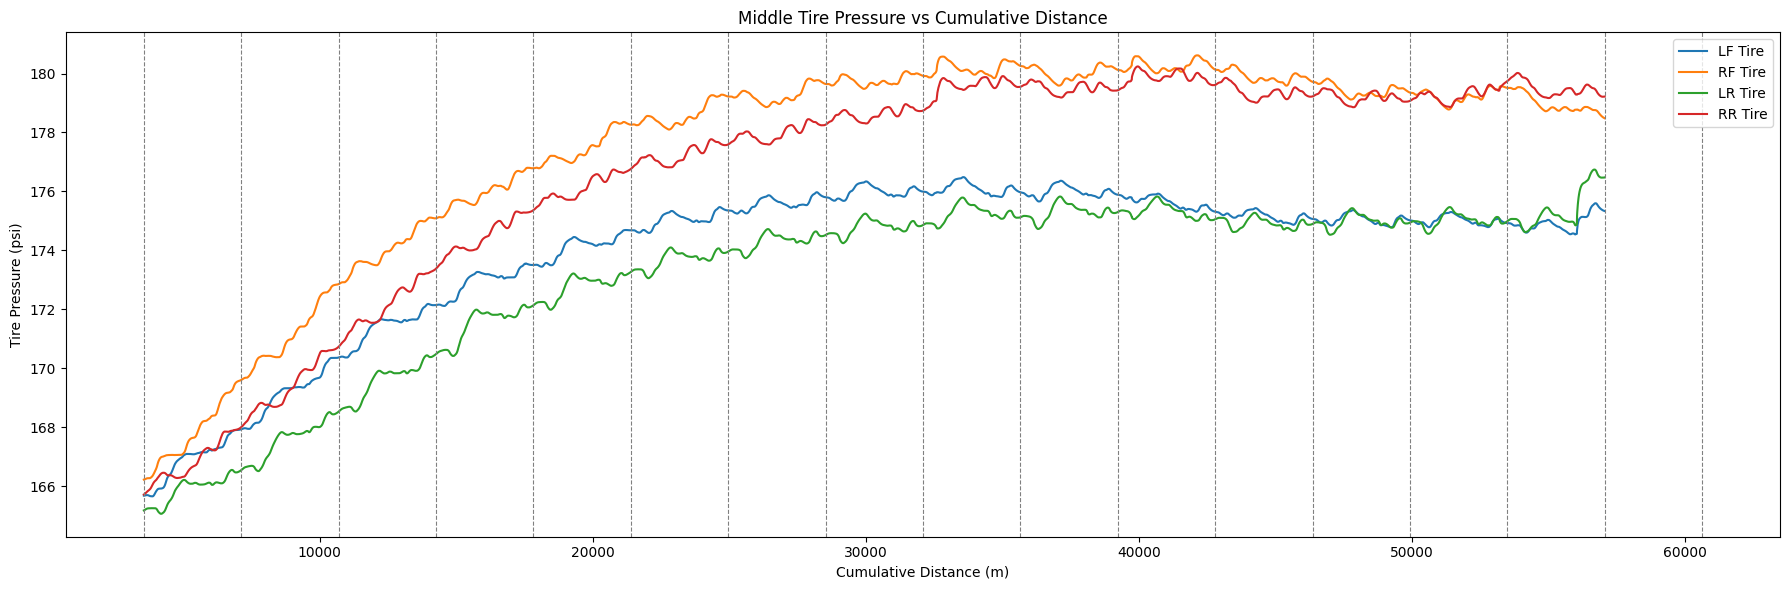

In [41]:
laps_to_plot = np.arange(1,16)

df_stint = df[(df["source_file"] == "porsche992cup_lagunaseca 2025-06-18 11-58-07_Stint_1.csv") & df["Lap"].isin(laps_to_plot)]  # adjust column name if needed

lap_starts = df.groupby("Lap")["CumulativeDist"].min().values

plt.figure(figsize=(18, 6))
for tire in ["LF", "RF", "LR", "RR"]:
    plt.plot(df_stint["CumulativeDist"], df_stint[f"{tire}pressure"], label=f"{tire} Tire")

# Add vertical lines for lap starts
for i, dist in enumerate(lap_starts):
    plt.axvline(x=dist, color='gray', linestyle='--', linewidth=0.8)

plt.title("Middle Tire Pressure vs Cumulative Distance")
plt.xlabel("Cumulative Distance (m)")
plt.ylabel("Tire Pressure (psi)")
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\cisan\AppData\Local\Temp\ipykernel_16792\3926628696.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap("tab10", len(ride_height_cols))


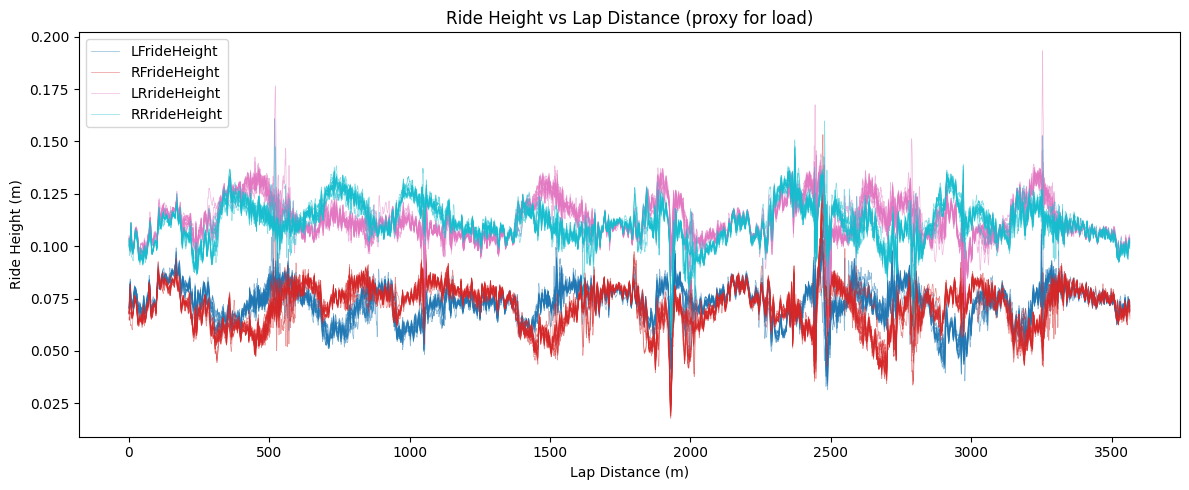

In [42]:
import matplotlib.cm as cm

plt.figure(figsize=(12, 5))

# for lap_num, lap_df in stint_df.groupby("Lap"):
#     for col in ride_height_cols:
#         plt.plot(lap_df["LapDist"], lap_df[col], color="red", alpha=0.5, linewidth=0.5, label=col)

colors = cm.get_cmap("tab10", len(ride_height_cols))

for i, col in enumerate(ride_height_cols):
    for lap_num, lap_df in stint_df.groupby("Lap"):
        plt.plot(lap_df["LapDist"], lap_df[col],
                 color=colors(i),
                 alpha=0.5,
                 linewidth=0.5,
                 label=col if lap_num == stint_df["Lap"].min() else "")  # only label once

plt.title("Ride Height vs Lap Distance (proxy for load)")
plt.ylabel("Ride Height (m)")
plt.xlabel("Lap Distance (m)")
plt.legend()
plt.tight_layout()
plt.show()



In [43]:
avg_ride_heights.head()

NameError: name 'avg_ride_heights' is not defined

C:\Users\cisan\AppData\Local\Temp\ipykernel_16792\3010067020.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap("tab10", len(ride_height_cols))


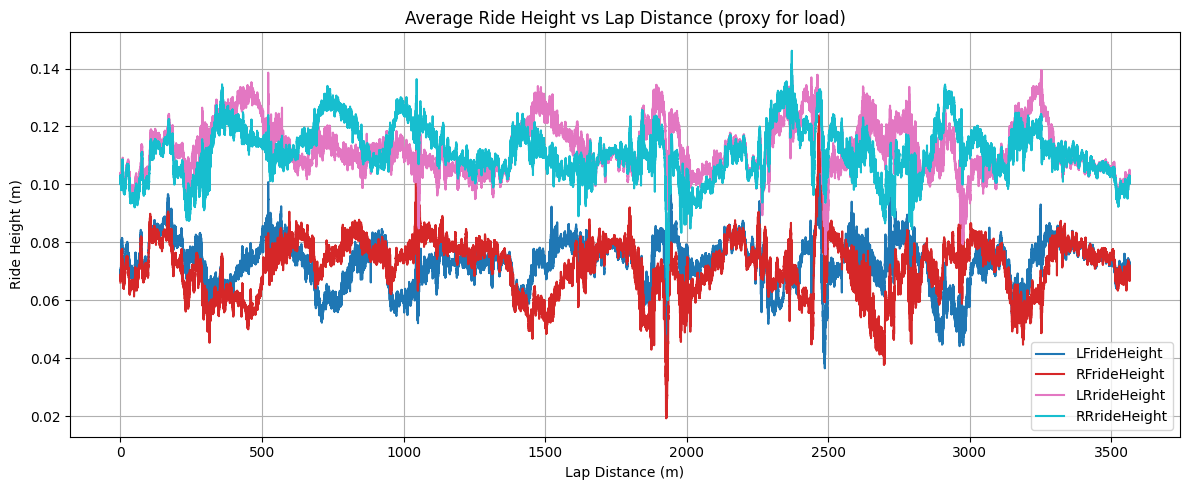

In [44]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Create color palette
colors = cm.get_cmap("tab10", len(ride_height_cols))

stint_df["LapDist_r1"] = stint_df["LapDist"].round(1)

# Group by LapDist and calculate mean for each ride height column
avg_ride_heights = stint_df.groupby("LapDist_r1")[ride_height_cols].mean().reset_index()

plt.figure(figsize=(12, 5))

# Plot average ride height for each tire
for i, col in enumerate(ride_height_cols):
    plt.plot(avg_ride_heights["LapDist_r1"], avg_ride_heights[col],
             color=colors(i),
             label=col,
             linewidth=1.5)

plt.title("Average Ride Height vs Lap Distance (proxy for load)")
plt.ylabel("Ride Height (m)")
plt.xlabel("Lap Distance (m)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [45]:
are_identical = (df['LRbrakeLinePress'] == df['RRbrakeLinePress']).all()
print(are_identical)

True


In [46]:
#random
laptimes = df.groupby(['source_file','Turn'])['LapCurrentLapTime'].max()